# Clinical–neural coupling of treatment-responsive effective connectivity

This section tests what two treatment-responsive ECs add to the clinical and cognitive longitudinal model. All direct model comparisons use the same imaging cohort. The eight-EC clinical PEB is a complementary analysis with neural parameters as outcomes.

Run the Python preparation, focused models and their figures first. The temporal-shape and PANSS-domain blocks are supporting analyses. Run `peb_section4_final.m` after `Neural_clinical_sample.csv` has been generated, then execute the final PEB reporting section. 

Running order:

1. Sections 1–8: prepare the shared sample and run the clinical models.

2. Run peb_section4_final.m in MATLAB: generate the five clinical-PEB result tables.

3. Return to 4a Section 9: read those tables.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# project PATH
DATASET_NAME = "sz_meditation"
project_path_str="/scratch/repo_"+DATASET_NAME
project_path= Path(project_path_str)
sys.path.append(str(project_path))

# importing private libs and functions (imaging_arsenal version, need to import the parent dir as well)
private_lib_path = Path('/scratch/imaging_arsenal')
sys.path.append(str(private_lib_path))
sys.path.append(str(private_lib_path / 'utils_'))
print('private lib ready:',(private_lib_path / 'utils_private.py').exists())
from utils_.utils_private import report_cpu, report_unified_missingness
report_cpu()

# data path
data_path = project_path / 'data' 
fig_path = project_path / 'fig' 

# data
basic_time_Tag = "20240724"
all_DKT_path = data_path / (DATASET_NAME+'_R_'+basic_time_Tag+'.csv')

# read data
all_df = pd.read_csv(all_DKT_path, index_col= None)

private lib ready: False


/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Total CPUs: 12
Total Memory: 29.38 GB
Available Memory: 22.40 GB


In [2]:
# report major software version
import statsmodels 
import nilearn
import sys
import sklearn
import semopy
import seaborn as sns
import networkx as nx
# setup random seed
rand_seed = 24
np.random.seed(rand_seed)

print('python version:', sys.version)
print('numpy version:', np.__version__)
print('statsmodels version:', statsmodels.__version__)
print('nilearn version:', nilearn.__version__)
print('sklearn version:', sklearn.__version__)
print('semopy version:', semopy.__version__)
print('networkX version:', nx.__version__)
print('seaborn version:', sns.__version__)
print('random seed:', rand_seed)

python version: 3.9.12 | packaged by conda-forge | (main, Mar 24 2022, 23:25:59) 
[GCC 10.3.0]
numpy version: 1.26.4
statsmodels version: 0.14.5
nilearn version: 0.12.0
sklearn version: 1.4.2
semopy version: 2.3.11
networkX version: 3.1
seaborn version: 0.13.2
random seed: 24


## 1. Read finalized Section 3 EC/motion data and original clinical records.

In [3]:
# Aim: rebuild the imaging-cohort inputs; method: participant/visit matching;
# output: raw EC, motion and clinical tables, independent of trajectory classes.
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

peb_path = data_path / 'dcm' / 'PEB_section3'
nc_path = data_path / 'neural_clinical'
nc_edges = pd.read_csv(peb_path / 'Selected_edge_dictionary.csv')
nc_brain = pd.read_csv(peb_path / 'DCM_selected_edges_all_available.csv',
                       dtype={'Participant_ID': str})
nc_brain = nc_brain.rename(columns={'Participant_ID': 'participant_id',
                                    'Session_Month': 'session', 'Group': 'group'})
nc_brain['session'] = pd.to_numeric(nc_brain['session'], errors='raise')
nc_brain['group'] = nc_brain['group'].str.strip().str.lower()
nc_discovery = nc_brain['In_PEB_Discovery'].astype(str).str.lower().isin(['1', '1.0', 'true'])
nc_brain = nc_brain.loc[nc_discovery & nc_brain.session.isin([0, 3, 8])].copy()
nc_ids = pd.Index(sorted(nc_brain.participant_id.unique()), name='participant_id')
nc_scores = ['PANSS_SUM', 'RBANS_sum', 'PANSS_P_SUM', 'PANSS_N_SUM', 'PANSS_G_SUM']
nc_baselines = ['PANSS_SUM_base', 'RBANS_sum_base']
nc_columns = ['participant_id', 'session', 'group', 'CPZ_dose_0'] + nc_scores + nc_baselines
nc_clinical = all_df[nc_columns].copy()
nc_clinical['participant_id'] = nc_clinical['participant_id'].astype(str)
nc_clinical['session'] = pd.to_numeric(nc_clinical['session'], errors='raise')
nc_clinical['group'] = nc_clinical['group'].str.strip().str.lower()
nc_clinical = nc_clinical.loc[nc_clinical.participant_id.isin(nc_ids) &
                              nc_clinical.session.isin([0, 3, 8])].copy()
nc_numeric = ['CPZ_dose_0'] + nc_scores + nc_baselines
nc_clinical[nc_numeric] = nc_clinical[nc_numeric].apply(pd.to_numeric, errors='raise')
nc_visits = {month: nc_clinical.loc[nc_clinical.session.eq(month)]
             .set_index('participant_id', verify_integrity=True).reindex(nc_ids)
             for month in [0, 3, 8]}
nc_brain_groups = nc_brain.pivot(index='participant_id', columns='session', values='group').reindex(nc_ids)
for month in [0, 3, 8]:
    present = nc_visits[month].group.notna() & nc_brain_groups[month].notna()
    if not nc_visits[month].loc[present, 'group'].eq(nc_brain_groups.loc[present, month]).all():
        raise ValueError('Clinical and DCM treatment labels disagree; resolve the source records before fitting.')

## 2. Define the common complete-case sample and rescale continuous inputs.


In [4]:
# Aim: reproduce the focused cohort; method: raw change definitions and observed ddof=0 SDs;
# output: one raw sample CSV for Python/MATLAB, plus in-memory standardized model inputs.
nc_raw = nc_visits[0][['group'] + nc_baselines].copy()
for score in nc_scores[2:]:
    nc_raw[score + '_base'] = nc_visits[0][score]
nc_raw['treatment'] = nc_raw.group.map({'control': 0, 'meditation': 1})
nc_raw['CPZ_dose'] = nc_visits[0]['CPZ_dose_0']
for month in [3, 8]:
    for score in (nc_scores if month == 3 else nc_scores[:2]):
        nc_raw[f'{score}_{month}'] = nc_visits[month][score]
    nc_raw[f'PANSS_dec_rate_{month}'] = (
        (nc_raw.PANSS_SUM_base - nc_raw[f'PANSS_SUM_{month}']) /
        (nc_raw.PANSS_SUM_base - 30).where(nc_raw.PANSS_SUM_base.gt(30)))
    nc_raw[f'RBANS_inc_rate_{month}'] = (
        (nc_raw[f'RBANS_sum_{month}'] - nc_raw.RBANS_sum_base) /
        nc_raw.RBANS_sum_base.where(nc_raw.RBANS_sum_base.gt(0)))
nc_fd = nc_brain.pivot(index='participant_id', columns='session', values='mean_fd').reindex(nc_ids)
for month in [0, 3, 8]:
    nc_raw[f'FD{month}'] = pd.to_numeric(nc_fd[month], errors='raise')
nc_focal_edges = nc_edges.loc[nc_edges.Source_Node.eq('IC02_SalVentA') &
                              nc_edges.Target_Node.isin(['IC00_SMN', 'IC18_SalVentB'])]
for edge in nc_focal_edges.itertuples(index=False):
    name = edge.Source_Node.split('_', 1)[1] + '_to_' + edge.Target_Node.split('_', 1)[1]
    ec = nc_brain.pivot(index='participant_id', columns='session', values=edge.CSV_Column).reindex(nc_ids)
    nc_raw['EC0_' + name] = ec[0]
    nc_raw['D3_' + name] = ec[3] - ec[0]
nc_model_columns = [
    'PANSS_dec_rate_3', 'RBANS_inc_rate_3', 'PANSS_dec_rate_8', 'RBANS_inc_rate_8',
    'treatment', 'PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose',
    'EC0_SalVentA_to_SMN', 'EC0_SalVentA_to_SalVentB',
    'D3_SalVentA_to_SMN', 'D3_SalVentA_to_SalVentB', 'FD0', 'FD3', 'FD8',
]
nc_required = nc_raw[nc_model_columns].apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
nc_missing = nc_required.isna()
print('Unavailable required values within the Section 3 discovery cohort:')
display(nc_missing.sum().loc[lambda x: x.gt(0)].rename('Missing_N').to_frame())
nc_sample = nc_raw.loc[~nc_missing.any(axis=1)].copy()
for score in ['PANSS_SUM', 'RBANS_sum']:
    for month in [0, 3, 8]:
        if not np.allclose(nc_visits[month].loc[nc_sample.index, score + '_base'],
                           nc_visits[0].loc[nc_sample.index, score], equal_nan=True):
            raise ValueError(f'{score}: baseline metadata differs across visits or from the actual baseline score.')
nc_continuous = [c for c in nc_model_columns if c != 'treatment']
nc_means = nc_sample[nc_continuous].mean()
nc_sds = nc_sample[nc_continuous].std(ddof=0)
fc_z = nc_sample[nc_model_columns].copy()
fc_z[nc_continuous] = (fc_z[nc_continuous] - nc_means) / nc_sds
fc_sd = fc_z.std(ddof=0)  # Fixed reference scales are retained during every omission.
nc_path.mkdir(parents=True, exist_ok=True)
nc_sample.to_csv(nc_path / 'Neural_clinical_sample.csv', index=True)
print(f'N={len(nc_sample)}; control={nc_sample.treatment.eq(0).sum()}; '
      f'meditation={nc_sample.treatment.eq(1).sum()}. No imputation or trajectory-class restriction.')
print('Two focal baseline ECs and their early changes; no trajectory-class restriction.')

Unavailable required values within the Section 3 discovery cohort:


,Missing_N
RBANS_inc_rate_3,1
RBANS_inc_rate_8,1
RBANS_sum_base,1


N=43; control=21; meditation=22. No imputation or trajectory-class restriction.
Two focal baseline ECs and their early changes; no trajectory-class restriction.


## 3. Define the three focused joint models on the same participant sample.

In [5]:

# Aim: separate baseline information from early changes; method: explicit recursive equations;
# output: clinical-only, baseline-EC and early-EC specifications with treatment-to-EC paths.
fc_outcomes = ['PANSS_dec_rate_3', 'RBANS_inc_rate_3',
               'PANSS_dec_rate_8', 'RBANS_inc_rate_8']
fc_base = ['EC0_SalVentA_to_SMN', 'EC0_SalVentA_to_SalVentB']
fc_delta = ['D3_SalVentA_to_SMN', 'D3_SalVentA_to_SalVentB']
fc_labels = dict(zip(fc_outcomes, ['PDR3', 'RIR3', 'PDR8', 'RIR8']))
fc_labels.update(dict(zip(fc_delta, ['IC02 → IC00 | early change', 'IC02 → IC18 | early change'])))
fc_names = ['1_Clinical+FD', '2_Two_baselines', '3_Two_early_changes']
fc_core = ['treatment', 'PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose']
fc_equations, fc_blocks = {}, {}
for name, extra in zip(fc_names, [[], fc_base, fc_base + fc_delta]):
    early = fc_core + extra + ['FD0', 'FD3']
    equations = {
        fc_outcomes[0]: early.copy(),
        fc_outcomes[1]: early.copy(),
        fc_outcomes[2]: fc_outcomes[:2] + early + ['FD8'],
        fc_outcomes[3]: fc_outcomes[1::-1] + early + ['FD8'],
    }
    if name == fc_names[2]:
        for delta in fc_delta:
            equations[delta] = fc_core + fc_base + ['FD0', 'FD3']
    equations['FD8'] = [fc_outcomes[0]] + early + [fc_outcomes[1]]
    fc_equations[name] = equations
    fc_blocks[name] = ([fc_delta] if name == fc_names[2] else []) + [fc_outcomes[:2], ['FD8'], fc_outcomes[2:]]
    print('\n' + name)
    for y, xs in equations.items():
        print(y + ' ~ ' + ' + '.join(xs))
    for ys in fc_blocks[name]:
        if len(ys) == 2:
            print(ys[0] + ' ~~ ' + ys[1])
print(f'\nSame N={len(fc_z)}: {fc_z.treatment.eq(0).sum()} control / '
      f'{fc_z.treatment.eq(1).sum()} meditation; same covariates and input scales.')
# Fixed two-edge follow-up after prior exploration; all four clinical outcomes retained.
# FD8 is auxiliary; both EC changes are 0–3 months. No new mediation test.


1_Clinical+FD
PANSS_dec_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3
RBANS_inc_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3
PANSS_dec_rate_8 ~ PANSS_dec_rate_3 + RBANS_inc_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3 + FD8
RBANS_inc_rate_8 ~ RBANS_inc_rate_3 + PANSS_dec_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3 + FD8
FD8 ~ PANSS_dec_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3 + RBANS_inc_rate_3
PANSS_dec_rate_3 ~~ RBANS_inc_rate_3
PANSS_dec_rate_8 ~~ RBANS_inc_rate_8

2_Two_baselines
PANSS_dec_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + EC0_SalVentA_to_SMN + EC0_SalVentA_to_SalVentB + FD0 + FD3
RBANS_inc_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + EC0_SalVentA_to_SMN + EC0_SalVentA_to_SalVentB + FD0 + FD3
PANSS_dec_rate_8 ~ PANSS_dec_rate_3 + RBANS_inc_rate_3 + treatment + PANSS_SUM_ba

## 4. Prepare and fit 4 models

In [6]:
# Aim: align estimation with the clinical cohort; method: StandardScaler on every
# modeled variable, including treatment; output: one shared imaging-cohort matrix.
import semopy
from sklearn.preprocessing import StandardScaler
from scipy.stats import norm

# Run the existing sample preparation and model-definition blocks first.
# nc_sample remains raw; fc_z remains available for the existing sensitivity code.
sem_raw = nc_sample[nc_model_columns].apply(pd.to_numeric, errors='raise').copy()
if not np.isfinite(sem_raw.to_numpy()).all():
    raise ValueError('The locked sample contains unavailable model inputs; do not drop a new subset here.')
sem_scaler = StandardScaler()
sem_data = pd.DataFrame(sem_scaler.fit_transform(sem_raw),
                       columns=sem_raw.columns, index=sem_raw.index)
sem_n = len(sem_raw)
sem_control_n = int(sem_raw.treatment.eq(0).sum())
sem_meditation_n = int(sem_raw.treatment.eq(1).sum())
print(f'semopy {semopy.__version__}; N={sem_n}, control={sem_control_n}, meditation={sem_meditation_n}.')
print('All variables, including treatment, use StandardScaler as in the clinical notebook.')

semopy 2.3.11; N=43, control=21, meditation=22.
All variables, including treatment, use StandardScaler as in the clinical notebook.


In [7]:
# Aim: distinguish cohort/FD alignment from adding neural information; method:
# the original clinical structure plus the three existing focused specifications;
# output: four explicit model strings, without changing the locked sample.
sem_clinical_equations = {
    fc_outcomes[0]: fc_core.copy(),
    fc_outcomes[1]: fc_core.copy(),
    fc_outcomes[2]: [fc_outcomes[0], fc_outcomes[1]] + fc_core,
    fc_outcomes[3]: [fc_outcomes[1], fc_outcomes[0]] + fc_core,
}
sem_equations = {'0_Clinical_original_covariates': sem_clinical_equations}
sem_equations.update(fc_equations)
sem_blocks = {'0_Clinical_original_covariates': [fc_outcomes[:2], fc_outcomes[2:]]}
sem_blocks.update(fc_blocks)
sem_specifications = {}
for model_name, equations in sem_equations.items():
    lines = [y + ' ~ ' + ' + '.join(xs) for y, xs in equations.items()]
    for ys in sem_blocks[model_name]:
        for j in range(len(ys)):
            for k in range(j + 1, len(ys)):
                lines.append(ys[j] + ' ~~ ' + ys[k])
    sem_specifications[model_name] = '\n'.join(lines)
    print('\n' + model_name + '\n' + sem_specifications[model_name])
# Model 0 mirrors the original clinical equations on these 43 participants.
# Models 1/2/3 retain the same FD adjustment; their differences are the neural additions.
# Keep the auxiliary FD8 equation in FD-adjusted models; it is not a biological path.


0_Clinical_original_covariates
PANSS_dec_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose
RBANS_inc_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose
PANSS_dec_rate_8 ~ PANSS_dec_rate_3 + RBANS_inc_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose
RBANS_inc_rate_8 ~ RBANS_inc_rate_3 + PANSS_dec_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose
PANSS_dec_rate_3 ~~ RBANS_inc_rate_3
PANSS_dec_rate_8 ~~ RBANS_inc_rate_8

1_Clinical+FD
PANSS_dec_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3
RBANS_inc_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3
PANSS_dec_rate_8 ~ PANSS_dec_rate_3 + RBANS_inc_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3 + FD8
RBANS_inc_rate_8 ~ RBANS_inc_rate_3 + PANSS_dec_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose + FD0 + FD3 + FD8
FD8 ~ PANSS_dec_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_

In [8]:
# Aim: use one estimation/inference convention throughout; method: native Model,
# fit defaults and inspect(std_est=True); output: fitted objects and tables in memory.
sem_models, sem_tables, sem_stats, sem_inputs = {}, {}, {}, {}
for model_name, specification in sem_specifications.items():
    variables = list(dict.fromkeys(
        list(sem_equations[model_name]) +
        [x for xs in sem_equations[model_name].values() for x in xs]))
    data_scaled = sem_data[variables].copy()
    model = semopy.Model(specification)
    fit_result = model.fit(data_scaled)
    if not fit_result.success or not np.isfinite(fit_result.fun):
        raise RuntimeError(f'{model_name}: native semopy fitting needs review.\n{fit_result}')
    results = model.inspect(std_est=True)
    sem_models[model_name] = model
    sem_tables[model_name] = results.copy()
    sem_inputs[model_name] = data_scaled
    sem_stats[model_name] = semopy.calc_stats(model)
    print('\n' + model_name)
    print(fit_result)
    display(results.loc[results.op.eq('~')])


0_Clinical_original_covariates
Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.000
Number of iterations: 22
Params: 0.692 0.116 0.171 -0.014 0.353 0.005 -0.014 -0.297 0.467 0.158 0.348 -0.151 -0.056 -0.137 0.577 0.173 0.077 -0.059 -0.297 -0.137 0.110 0.394 -0.060 0.274 0.787 0.492


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,PANSS_dec_rate_3,~,treatment,0.691795,0.691781,0.104569,6.615660,3.698974e-11
1,PANSS_dec_rate_3,~,PANSS_SUM_base,0.115841,0.115838,0.098106,1.180765,2.376959e-01
2,PANSS_dec_rate_3,~,RBANS_sum_base,0.171201,0.171198,0.109513,1.563300,1.179820e-01
3,PANSS_dec_rate_3,~,CPZ_dose,-0.014481,-0.014481,0.098974,-0.146314,8.836736e-01
4,RBANS_inc_rate_3,~,treatment,0.353318,0.353319,0.147759,2.391182,1.679425e-02
5,RBANS_inc_rate_3,~,PANSS_SUM_base,0.005364,0.005364,0.138627,0.038694,9.691340e-01
6,RBANS_inc_rate_3,~,RBANS_sum_base,-0.014251,-0.014251,0.154744,-0.092094,9.266234e-01
7,RBANS_inc_rate_3,~,CPZ_dose,-0.296686,-0.296686,0.139852,-2.121421,3.388643e-02
8,PANSS_dec_rate_8,~,PANSS_dec_rate_3,0.466667,0.466710,0.129852,3.593839,3.258410e-04
9,PANSS_dec_rate_8,~,RBANS_inc_rate_3,0.157598,0.157609,0.091896,1.714956,8.635321e-02



1_Clinical+FD
Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.000
Number of iterations: 25
Params: 0.743 0.141 0.148 -0.010 -0.235 0.285 0.390 -0.019 -0.051 -0.304 -0.101 0.032 0.412 0.137 0.462 -0.183 -0.119 -0.136 -0.178 0.120 -0.075 0.615 0.143 0.086 -0.013 -0.256 -0.156 -0.118 0.109 0.155 -0.143 0.190 -0.050 -0.139 0.173 0.289 0.257 -0.206 0.104 0.353 -0.057 0.255 0.562 0.781 0.468


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,PANSS_dec_rate_3,~,treatment,0.742707,0.742672,0.109939,6.755653,1.421929e-11
1,PANSS_dec_rate_3,~,PANSS_SUM_base,0.141306,0.141299,0.102882,1.373480,1.696033e-01
2,PANSS_dec_rate_3,~,RBANS_sum_base,0.147982,0.147975,0.114810,1.288924,1.974244e-01
3,PANSS_dec_rate_3,~,CPZ_dose,-0.010084,-0.010084,0.094417,-0.106806,9.149427e-01
4,PANSS_dec_rate_3,~,FD0,-0.235386,-0.235375,0.139712,-1.684790,9.202903e-02
5,PANSS_dec_rate_3,~,FD3,0.284554,0.284540,0.129759,2.192938,2.831188e-02
6,RBANS_inc_rate_3,~,treatment,0.390212,0.390253,0.163563,2.385698,1.704675e-02
7,RBANS_inc_rate_3,~,PANSS_SUM_base,-0.019155,-0.019157,0.153064,-0.125141,9.004121e-01
8,RBANS_inc_rate_3,~,RBANS_sum_base,-0.050681,-0.050687,0.170811,-0.296711,7.666872e-01
9,RBANS_inc_rate_3,~,CPZ_dose,-0.303663,-0.303695,0.140471,-2.161757,3.063690e-02



2_Two_baselines
Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.000
Number of iterations: 27
Params: 0.748 0.158 0.155 0.043 -0.176 0.122 -0.231 0.329 0.374 -0.053 -0.061 -0.419 0.385 -0.287 -0.106 -0.071 0.417 0.132 0.464 -0.188 -0.128 -0.142 0.017 0.010 -0.181 0.122 -0.079 0.552 0.223 0.052 -0.041 -0.281 -0.224 0.150 -0.078 -0.119 0.055 0.173 -0.239 0.271 -0.046 -0.169 0.225 -0.110 0.275 0.242 0.368 -0.119 0.160 0.328 -0.058 0.255 0.514 0.657 0.456


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,PANSS_dec_rate_3,~,treatment,0.748222,0.748194,0.107583,6.954805,3.530509e-12
1,PANSS_dec_rate_3,~,PANSS_SUM_base,0.158091,0.158085,0.100479,1.573373,1.156326e-01
2,PANSS_dec_rate_3,~,RBANS_sum_base,0.155436,0.155430,0.114039,1.363012,1.728786e-01
3,PANSS_dec_rate_3,~,CPZ_dose,0.042898,0.042896,0.096312,0.445403,6.560289e-01
4,PANSS_dec_rate_3,~,EC0_SalVentA_to_SMN,-0.176432,-0.176426,0.101647,-1.735739,8.261005e-02
5,PANSS_dec_rate_3,~,EC0_SalVentA_to_SalVentB,0.121913,0.121909,0.101376,1.202589,2.291353e-01
6,PANSS_dec_rate_3,~,FD0,-0.231290,-0.231281,0.135859,-1.702426,8.867557e-02
7,PANSS_dec_rate_3,~,FD3,0.328946,0.328933,0.129125,2.547502,1.084972e-02
8,RBANS_inc_rate_3,~,treatment,0.373891,0.373879,0.152297,2.455022,1.408760e-02
9,RBANS_inc_rate_3,~,PANSS_SUM_base,-0.053111,-0.053110,0.142240,-0.373393,7.088557e-01



3_Two_early_changes
Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.000
Number of iterations: 29
Params: 0.733 0.095 0.155 0.028 -0.049 0.027 0.185 -0.154 -0.238 0.282 0.421 -0.066 -0.044 -0.384 0.393 -0.456 0.017 -0.234 -0.139 -0.111 0.416 0.116 0.521 -0.172 -0.105 -0.118 -0.019 -0.128 -0.061 -0.163 -0.222 0.093 -0.046 0.541 0.205 0.094 -0.048 -0.262 -0.218 0.168 -0.194 0.022 -0.148 -0.155 0.023 0.209 0.264 0.317 0.070 0.215 -0.702 -0.094 -0.088 0.122 0.220 -0.032 0.078 0.163 -0.017 -0.727 -0.147 -0.160 -0.174 0.167 -0.016 -0.195 0.204 -0.169 0.492 -0.092 0.311 0.298 0.410 -0.089 -0.013 0.370 0.144 0.305 -0.066 0.244 0.394 0.474 0.635 0.448


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,PANSS_dec_rate_3,~,treatment,0.733222,0.733212,0.114250,6.417678,1.383686e-10
1,PANSS_dec_rate_3,~,PANSS_SUM_base,0.094520,0.094519,0.106449,0.887938,3.745741e-01
2,PANSS_dec_rate_3,~,RBANS_sum_base,0.154568,0.154566,0.110965,1.392949,1.636353e-01
3,PANSS_dec_rate_3,~,CPZ_dose,0.028370,0.028370,0.100211,0.283103,7.770977e-01
4,PANSS_dec_rate_3,~,EC0_SalVentA_to_SMN,-0.049347,-0.049347,0.138192,-0.357093,7.210224e-01
...,...,...,...,...,...,...,...,...
69,RBANS_inc_rate_8,~,D3_SalVentA_to_SMN,0.022237,0.022238,0.172178,0.129152,8.972371e-01
70,RBANS_inc_rate_8,~,D3_SalVentA_to_SalVentB,-0.148229,-0.148232,0.172865,-0.857487,3.911760e-01
71,RBANS_inc_rate_8,~,FD0,-0.155369,-0.155367,0.173075,-0.897701,3.693452e-01
72,RBANS_inc_rate_8,~,FD3,0.022663,0.022663,0.177092,0.127973,8.981703e-01


In [9]:
# Aim: make figures traceable to the semopy models; method: returned estimates,
# native Wald inference and directly evaluated equations; output: two scientific CSVs.
sem_path_rows, sem_outcome_rows = [], []
sem_zcrit = norm.ppf(0.975)
for model_name, model in sem_models.items():
    table = sem_tables[model_name].copy()
    data_scaled = sem_inputs[model_name]
    sigma = model.calc_sigma()[0]
    model_sd = pd.Series(np.sqrt(np.diag(sigma)), index=model.vars['observed'])
    table['Model'] = model_name
    table['N'] = sem_n
    table['Control_N'] = sem_control_n
    table['Meditation_N'] = sem_meditation_n
    table['Beta'] = pd.to_numeric(table['Est. Std'], errors='coerce')
    table['SEM_SE_Estimate'] = pd.to_numeric(table['Std. Err'], errors='coerce')
    table['SEM_CI95_low_Estimate'] = table.Estimate - sem_zcrit * table.SEM_SE_Estimate
    table['SEM_CI95_high_Estimate'] = table.Estimate + sem_zcrit * table.SEM_SE_Estimate
    table['SEM_p_nominal'] = pd.to_numeric(table['p-value'], errors='coerce')
    table['Formula'] = [y + ' ~ ' + ' + '.join(sem_equations[model_name][y])
                         if op == '~' else 'Residual variance/covariance'
                         for y, op in zip(table.lval, table.op)]
    table['Auxiliary'] = table.lval.eq('FD8')
    # Standardized intervals rescale native Wald endpoints with fitted SDs held fixed.
    # They are not a separate delta-method interval for uncertainty in the SD estimates.
    regressions = table.op.eq('~')
    scale = [model_sd[x] / model_sd[y]
             for y, x in zip(table.loc[regressions, 'lval'], table.loc[regressions, 'rval'])]
    table.loc[regressions, 'SEM_CI95_low_Beta_plugin'] = (
        table.loc[regressions, 'SEM_CI95_low_Estimate'].to_numpy() * np.asarray(scale))
    table.loc[regressions, 'SEM_CI95_high_Beta_plugin'] = (
        table.loc[regressions, 'SEM_CI95_high_Estimate'].to_numpy() * np.asarray(scale))
    table['Inference'] = 'semopy native expected information; nonrobust Wald z'
    table['Semopy_version'] = semopy.__version__
    sem_path_rows.append(table)

    observed_n = len(model.vars['observed'])
    exogenous_n = len(set(model.vars['observed']) & set(model.vars['exogenous']))
    free_n = sum(parameter.active for parameter in model.parameters.values())
    conditional_df = (observed_n * (observed_n + 1) // 2 -
                      exogenous_n * (exogenous_n + 1) // 2 - free_n)
    for outcome in fc_outcomes:
        predictors = sem_equations[model_name][outcome]
        slopes = table.loc[table.op.eq('~') & table.lval.eq(outcome)].set_index('rval')['Estimate']
        fitted_values = data_scaled[predictors].to_numpy() @ slopes.loc[predictors].to_numpy()
        observed = data_scaled[outcome].to_numpy()
        r2 = 1 - np.sum((observed - fitted_values) ** 2) / np.sum((observed - observed.mean()) ** 2)
        residual_df = sem_n - len(predictors) - 1
        sem_outcome_rows.append({
            'Model': model_name, 'Outcome': outcome, 'Outcome_label': fc_labels[outcome],
            'N': sem_n, 'Control_N': sem_control_n, 'Meditation_N': sem_meditation_n,
            'Predictors': len(predictors), 'Residual_df_for_adjusted_R2': residual_df,
            'In_sample_R2': r2, 'Adjusted_R2': 1 - (1-r2) * (sem_n-1) / residual_df,
            'Conditional_df': conditional_df, 'Native_MLW': float(model.last_result.fun),
            'Native_semopy_df': float(sem_stats[model_name].loc['Value', 'DoF']),
            'Inference': 'semopy native expected information; nonrobust Wald z',
            'Semopy_version': semopy.__version__,
        })
sem_paths = pd.concat(sem_path_rows, ignore_index=True)
sem_outcomes = pd.DataFrame(sem_outcome_rows)
for metric in ['In_sample_R2', 'Adjusted_R2']:
    for reference, label in [(fc_names[0], 'clinical_FD'), (fc_names[1], 'two_baselines')]:
        values = sem_outcomes.loc[sem_outcomes.Model.eq(reference)].set_index('Outcome')[metric]
        sem_outcomes['Delta_' + metric + '_vs_' + label] = (
            sem_outcomes[metric] - sem_outcomes.Outcome.map(values))
sem_paths.to_csv(nc_path / 'Focused_CLPM_semopy_paths.csv', index=False)
sem_outcomes.to_csv(nc_path / 'Focused_CLPM_semopy_outcomes.csv', index=False)
display(sem_outcomes[['Model', 'Outcome_label', 'N', 'In_sample_R2', 'Adjusted_R2', 'Conditional_df']])
sem_focal = sem_paths.loc[sem_paths.Model.eq(fc_names[2]) & sem_paths.op.eq('~') &
                         ((sem_paths.lval.isin(fc_outcomes) & sem_paths.rval.isin(fc_delta)) |
                          (sem_paths.lval.isin(fc_delta) & sem_paths.rval.eq('treatment')))]
display(sem_focal[['lval', 'rval', 'Estimate', 'Beta', 'SEM_CI95_low_Estimate',
                   'SEM_CI95_high_Estimate', 'SEM_p_nominal']])
print('Saved the two semopy tables to:', nc_path)
# R2 comes from the fitted structural slopes, not model.predict on observed outcomes.
# Native semopy global df includes fixed-exogenous moments; conditional saturation
# is the relevant limitation here. Do not use excellent global fit as validation or
# difference-test joint fit statistics from models containing different variable sets.

,Model,Outcome_label,N,In_sample_R2,Adjusted_R2,Conditional_df
0,0_Clinical_original_covariates,PDR3,43,0.606245,0.564797,0
1,0_Clinical_original_covariates,RIR3,43,0.213439,0.130643,0
2,0_Clinical_original_covariates,PDR8,43,0.725647,0.679921,0
3,0_Clinical_original_covariates,RIR8,43,0.508050,0.426058,0
4,1_Clinical+FD,PDR3,43,0.646974,0.588137,0
5,1_Clinical+FD,RIR3,43,0.218337,0.088059,0
6,1_Clinical+FD,PDR8,43,0.744974,0.675422,0
7,1_Clinical+FD,RIR8,43,0.532011,0.404378,0
8,2_Two_baselines,PDR3,43,0.672330,0.595231,0
9,2_Two_baselines,RIR3,43,0.343323,0.188810,0


,lval,rval,Estimate,Beta,SEM_CI95_low_Estimate,SEM_CI95_high_Estimate,SEM_p_nominal
132,PANSS_dec_rate_3,D3_SalVentA_to_SMN,0.184821,0.184827,-0.086700,0.456341,0.182163
133,PANSS_dec_rate_3,D3_SalVentA_to_SalVentB,-0.154099,-0.154103,-0.417133,0.108935,0.250865
142,RBANS_inc_rate_3,D3_SalVentA_to_SMN,0.016962,0.016963,-0.374823,0.408748,0.932375
143,RBANS_inc_rate_3,D3_SalVentA_to_SalVentB,-0.234040,-0.234046,-0.613580,0.145500,0.226819
146,D3_SalVentA_to_SMN,treatment,0.264108,0.264095,0.040067,0.488149,0.020862
154,D3_SalVentA_to_SalVentB,treatment,0.219820,0.219812,-0.011450,0.451089,0.062472
182,PANSS_dec_rate_8,D3_SalVentA_to_SMN,-0.060987,-0.060990,-0.309966,0.187992,0.631165
183,PANSS_dec_rate_8,D3_SalVentA_to_SalVentB,-0.163193,-0.163199,-0.413165,0.086779,0.200703
195,RBANS_inc_rate_8,D3_SalVentA_to_SMN,0.022237,0.022238,-0.315226,0.359700,0.897237
196,RBANS_inc_rate_8,D3_SalVentA_to_SalVentB,-0.148229,-0.148232,-0.487039,0.190580,0.391176


Saved the two semopy tables to: /scratch/repo_sz_meditation/data/neural_clinical


### 5. Diagram visualization 

In [10]:
# %% 1. Prepare the four fitted models for reference diagrams.
# Aim: use the current native semopy fits; method: copy their result variables;
# output: plotting tables and labels, without loading old results or fitting models.
import json
import numpy as np
import pandas as pd
from IPython.display import display

clpm_save_figs = 0
clpm_fig_dir = fig_path / 'neural_clinical'

clpm_paths = sem_paths.copy()
clpm_outcomes = sem_outcomes.copy()

clpm_model_names = {
    '0_Clinical_original_covariates': 'Model 1: clinical model, original covariates',
    '1_Clinical+FD': 'Model 2: clinical model with motion adjustment',
    '2_Two_baselines': 'Model 3: clinical model with baseline ECs',
    '3_Two_early_changes': 'Model 4: clinical model with baseline and early EC changes',
}
clpm_clinical = ['PANSS_dec_rate_3', 'RBANS_inc_rate_3',
                 'PANSS_dec_rate_8', 'RBANS_inc_rate_8']
clpm_baseline = ['EC0_SalVentA_to_SMN', 'EC0_SalVentA_to_SalVentB']
clpm_change = ['D3_SalVentA_to_SMN', 'D3_SalVentA_to_SalVentB']
clpm_nuisance = ['PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose', 'FD0', 'FD3', 'FD8']
clpm_labels = {
    'treatment': 'Meditation\nversus control',
    'PANSS_dec_rate_3': 'Symptom improvement\nPDR (3 months)',
    'RBANS_inc_rate_3': 'Cognitive improvement\nRIR (3 months)',
    'PANSS_dec_rate_8': 'Symptom improvement\nPDR (8 months)',
    'RBANS_inc_rate_8': 'Cognitive improvement\nRIR (8 months)',
    'EC0_SalVentA_to_SMN': 'IC02 SMG-VAN → IC00 SMN\nBaseline EC',
    'EC0_SalVentA_to_SalVentB': 'IC02 SMG-VAN → IC18 MFG-VAN/FPN\nBaseline EC',
    'D3_SalVentA_to_SMN': 'IC02 SMG-VAN → IC00 SMN\nEC change (0–3 months)',
    'D3_SalVentA_to_SalVentB': 'IC02 SMG-VAN → IC18 MFG-VAN/FPN\nEC change (0–3 months)',
    'PANSS_SUM_base': 'Baseline PANSS', 'RBANS_sum_base': 'Baseline RBANS',
    'CPZ_dose': 'Baseline CPZ dose', 'FD0': 'Baseline FD',
    'FD3': 'Month-3 FD', 'FD8': 'Month-8 FD\nAuxiliary equation',
}
clpm_short = dict(zip(clpm_clinical, ['PDR3', 'RIR3', 'PDR8', 'RIR8']))
clpm_short.update({
    'treatment': 'Treatment',
    'EC0_SalVentA_to_SMN': 'Baseline IC02 → IC00',
    'EC0_SalVentA_to_SalVentB': 'Baseline IC02 → IC18',
    'D3_SalVentA_to_SMN': 'Change IC02 → IC00',
    'D3_SalVentA_to_SalVentB': 'Change IC02 → IC18',
})
# The display numbers 1–4 correspond to the saved model IDs 0–3; the fits are unchanged.

In [11]:
# %% 2. Define a result-driven Graphviz diagram.
# Aim: show the fitted structure; method: draw all paths between displayed nodes;
# output: DOT text and, when requested, the exact fitted rows used for its arrows.
def clpm_stars(p):
    if not np.isfinite(p):
        return ''
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return ' (n.s.)'

def clpm_graph_source(model_name, show_covariates=False, show_residual_variances=False,
                      return_paths=False):
    table = clpm_paths.loc[clpm_paths.Model.eq(model_name)].copy()
    info = clpm_outcomes.loc[clpm_outcomes.Model.eq(model_name)].iloc[0]
    slopes = table.loc[table.op.eq('~')]
    all_nodes = set(slopes.lval) | set(slopes.rval)
    visible = all_nodes if show_covariates else all_nodes - set(clpm_nuisance)
    plotted = slopes.loc[slopes.lval.isin(visible) & slopes.rval.isin(visible)]
    residuals = table.loc[table.op.eq('~~') & table.lval.isin(visible) & table.rval.isin(visible)]
    covariances = residuals.loc[residuals.lval.ne(residuals.rval)]
    variances = residuals.loc[residuals.lval.eq(residuals.rval)].set_index('lval')
    node_order = [x for x in clpm_labels if x in visible] + sorted(visible - set(clpm_labels))
    quote = lambda value: json.dumps(str(value), ensure_ascii=False)
    title = (clpm_model_names[model_name] + '\n' +
             f'N = {int(info.N)}; control = {int(info.Control_N)}, meditation = {int(info.Meditation_N)}'
             + f' | standardized β | {len(plotted)} regression paths shown')
    lines = ['digraph CLPM {',
             'graph [rankdir=LR, splines=spline, nodesep=0.65, ranksep=1.3,',
             '       bgcolor="white", pad=0.3, outputorder=edgesfirst,',
             '       fontname="Arial", fontsize=18, labelloc=t];',
             'label=' + quote(title) + ';',
             'node [shape=box, style="rounded,filled", color="#28323c",',
             '      fontname="Arial", fontsize=14, penwidth=1.8, margin="0.2,0.12"];',
             'edge [fontname="Arial", fontsize=12, arrowsize=0.8];']
    for variable in node_order:
        fill = '#ffffff'
        if variable == 'treatment':
            fill = '#e5eaee'
        elif variable in clpm_baseline:
            fill = '#eef4f7'
        elif variable in clpm_change:
            fill = '#fff3d9'
        elif variable in clpm_nuisance:
            fill = '#f2f2f2'
        label = clpm_labels.get(variable, variable)
        if show_residual_variances and variable in variances.index:
            label += f'\nResidual variance = {float(variances.loc[variable, "Beta"]):.3f}'
        group = ('symptom' if variable in clpm_clinical[::2]
                 else 'cognition' if variable in clpm_clinical[1::2] else variable)
        lines.append(quote(variable) + ' [label=' + quote(label) +
                     ', fillcolor=' + quote(fill) + ', group=' + quote(group) + '];')
    # Columns describe the equations, not causal timing within the early window.
    ranks = [['treatment'] + clpm_baseline + clpm_nuisance[:-1],
             clpm_change, clpm_clinical[:2], ['FD8'], clpm_clinical[2:]]
    for rank in ranks:
        nodes = [quote(x) for x in rank if x in visible]
        if nodes:
            lines.append('{ rank=same; ' + '; '.join(nodes) + '; }')
    for row in plotted.itertuples(index=False):
        p = float(row.SEM_p_nominal)
        color = '#243746' if p < 0.05 else '#858b92'
        style = 'solid' if p < 0.05 else 'dashed'
        label = f'β = {row.Beta:+.3f}' + clpm_stars(p)
        weight = 20 if (row.rval, row.lval) in list(zip(clpm_clinical[:2], clpm_clinical[2:])) else 1
        lines.append(f'{quote(row.rval)} -> {quote(row.lval)} [label={quote(label)}, '
                     f'color={quote(color)}, fontcolor={quote(color)}, style={quote(style)}, '
                     f'penwidth=2.2, weight={weight}];')
    for row in covariances.itertuples(index=False):
        first, second = sorted([row.lval, row.rval], key=node_order.index)
        label = f'ψ = {row.Beta:+.3f}'
        lines.append(f'{quote(first)} -> {quote(second)} [dir=both, constraint=false, '
                     f'label={quote(label)}, color="#9a9fa5", fontcolor="#767b81", '
                     'style=dotted, penwidth=1.3];')
    lines.append('}')
    if return_paths:
        return '\n'.join(lines), plotted.copy(), covariances.copy()
    return '\n'.join(lines)
# ψ denotes standardized residual covariance, not residual correlation.
# No path is removed because its p-value is nonsignificant.

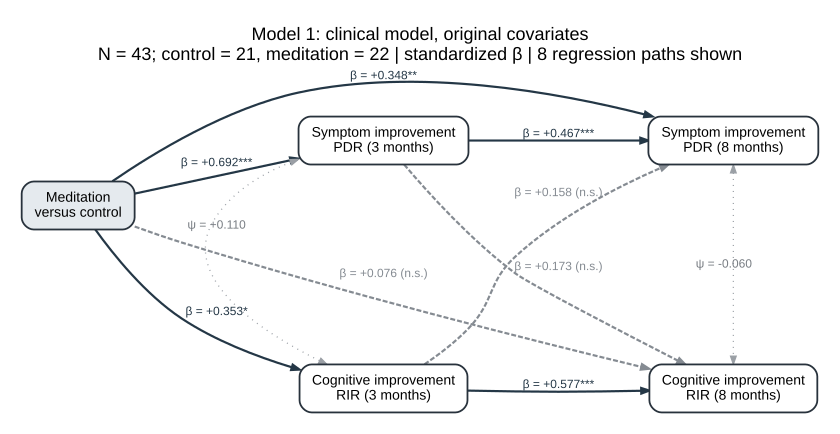

Model 1: clinical model, original covariates | 8 visible regression paths


,Source,Target,Beta,SEM_CI95_low_Beta_plugin,SEM_CI95_high_Beta_plugin,SEM_p_nominal,Diagram_label
0,Treatment,PDR3,+0.692,+0.487,+0.897,3.699e-11,β = +0.692***
1,Treatment,RIR3,+0.353,+0.064,+0.643,0.01679,β = +0.353*
2,PDR3,PDR8,+0.467,+0.212,+0.721,0.0003258,β = +0.467***
3,RIR3,PDR8,+0.158,-0.023,+0.338,0.08635,β = +0.158 (n.s.)
4,Treatment,PDR8,+0.348,+0.104,+0.593,0.005247,β = +0.348**
5,RIR3,RIR8,+0.577,+0.336,+0.818,2.756e-06,β = +0.577***
6,PDR3,RIR8,+0.173,-0.168,+0.513,0.321,β = +0.173 (n.s.)
7,Treatment,RIR8,+0.076,-0.251,+0.404,0.6472,β = +0.076 (n.s.)


Visible residual covariances (ψ):


,Node_1,Node_2,Standardized_residual_covariance,SEM_p_nominal,Diagram_label
0,PDR3,RIR3,+0.110,0.2019,ψ = +0.110
1,PDR8,RIR8,-0.060,0.2941,ψ = -0.060


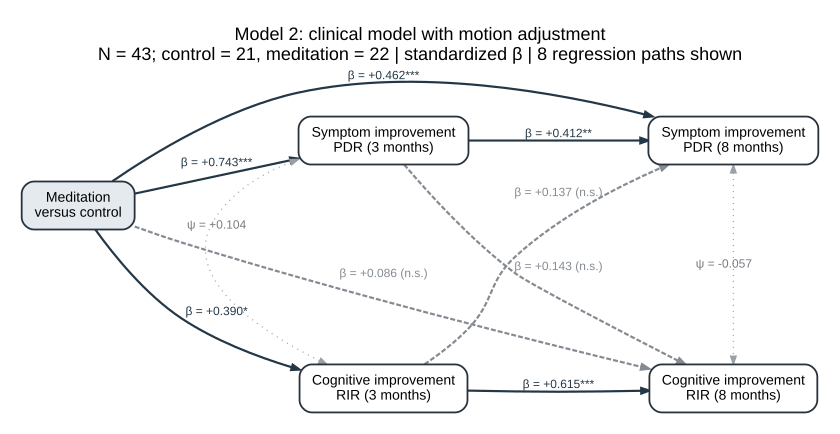

Model 2: clinical model with motion adjustment | 8 visible regression paths


,Source,Target,Beta,SEM_CI95_low_Beta_plugin,SEM_CI95_high_Beta_plugin,SEM_p_nominal,Diagram_label
0,Treatment,PDR3,+0.743,+0.527,+0.958,1.422e-11,β = +0.743***
1,Treatment,RIR3,+0.390,+0.070,+0.711,0.01705,β = +0.390*
2,PDR3,PDR8,+0.412,+0.151,+0.673,0.001955,β = +0.412**
3,RIR3,PDR8,+0.137,-0.042,+0.316,0.1329,β = +0.137 (n.s.)
4,Treatment,PDR8,+0.462,+0.194,+0.729,0.0007158,β = +0.462***
5,RIR3,RIR8,+0.615,+0.373,+0.858,6.629e-07,β = +0.615***
6,PDR3,RIR8,+0.143,-0.211,+0.496,0.4287,β = +0.143 (n.s.)
7,Treatment,RIR8,+0.086,-0.276,+0.448,0.6413,β = +0.086 (n.s.)


Visible residual covariances (ψ):


,Node_1,Node_2,Standardized_residual_covariance,SEM_p_nominal,Diagram_label
0,PDR3,RIR3,+0.104,0.204,ψ = +0.104
1,PDR8,RIR8,-0.057,0.2865,ψ = -0.057


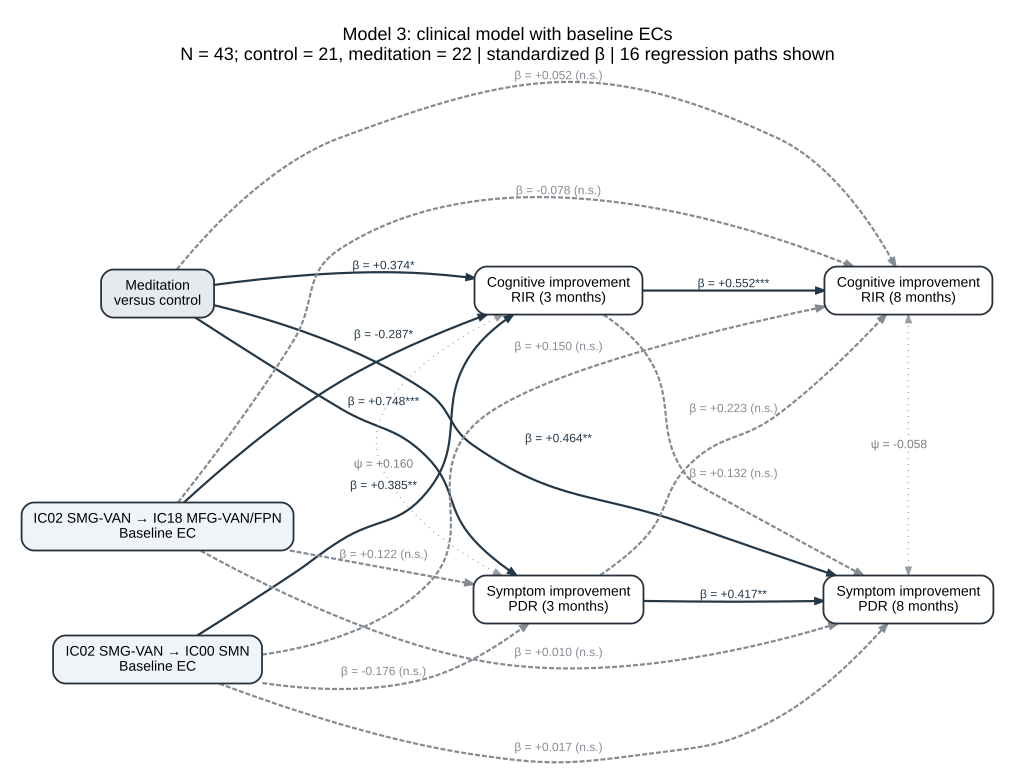

Model 3: clinical model with baseline ECs | 16 visible regression paths


,Source,Target,Beta,SEM_CI95_low_Beta_plugin,SEM_CI95_high_Beta_plugin,SEM_p_nominal,Diagram_label
0,Treatment,PDR3,+0.748,+0.537,+0.959,3.531e-12,β = +0.748***
1,Baseline IC02 → IC00,PDR3,-0.176,-0.376,+0.023,0.08261,β = -0.176 (n.s.)
2,Baseline IC02 → IC18,PDR3,+0.122,-0.077,+0.321,0.2291,β = +0.122 (n.s.)
3,Treatment,RIR3,+0.374,+0.075,+0.672,0.01409,β = +0.374*
4,Baseline IC02 → IC00,RIR3,+0.385,+0.103,+0.667,0.007532,β = +0.385**
5,Baseline IC02 → IC18,RIR3,-0.287,-0.568,-0.006,0.04552,β = -0.287*
6,PDR3,PDR8,+0.417,+0.132,+0.702,0.004185,β = +0.417**
7,RIR3,PDR8,+0.132,-0.068,+0.332,0.1951,β = +0.132 (n.s.)
8,Treatment,PDR8,+0.464,+0.187,+0.741,0.001024,β = +0.464**
9,Baseline IC02 → IC00,PDR8,+0.017,-0.189,+0.222,0.8732,β = +0.017 (n.s.)


Visible residual covariances (ψ):


,Node_1,Node_2,Standardized_residual_covariance,SEM_p_nominal,Diagram_label
0,PDR3,RIR3,+0.160,0.03258,ψ = +0.160
1,PDR8,RIR8,-0.058,0.2693,ψ = -0.058


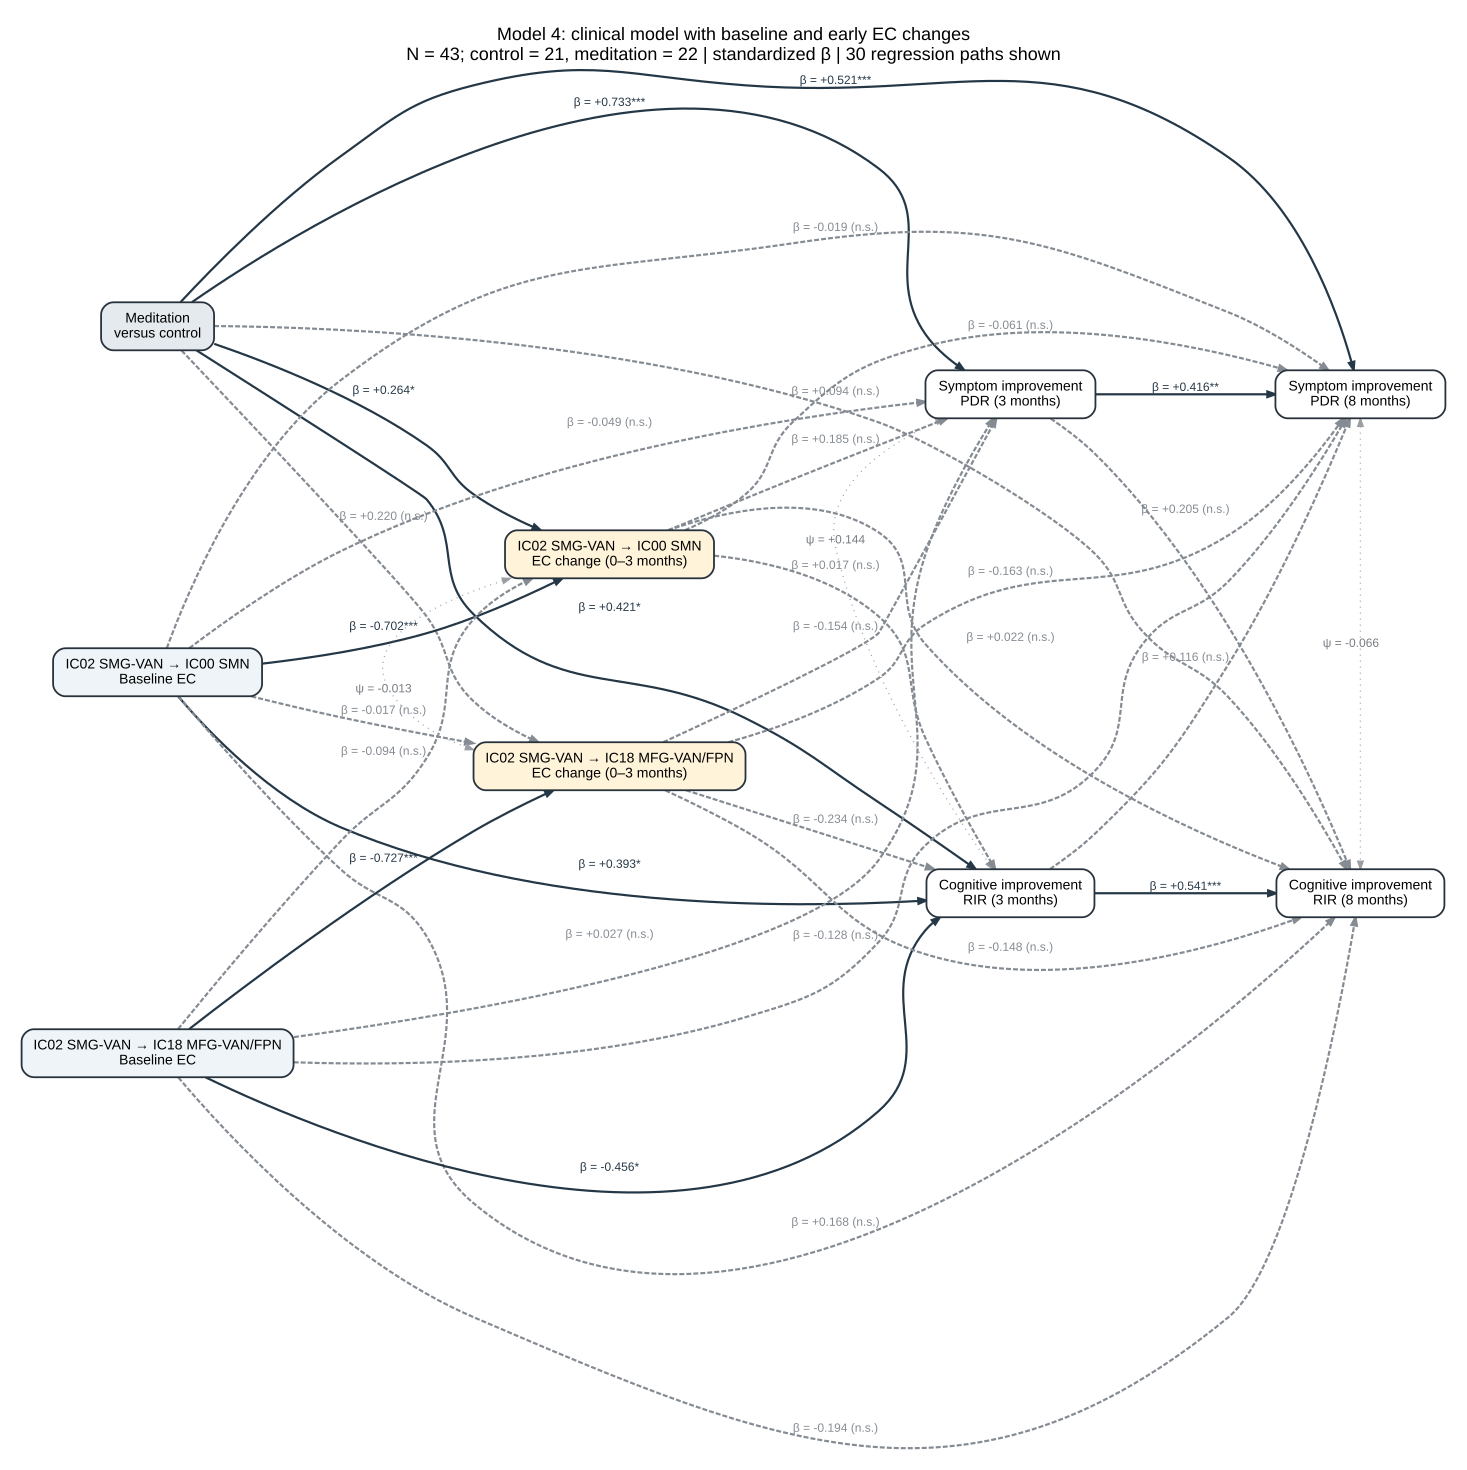

Model 4: clinical model with baseline and early EC changes | 30 visible regression paths


,Source,Target,Beta,SEM_CI95_low_Beta_plugin,SEM_CI95_high_Beta_plugin,SEM_p_nominal,Diagram_label
0,Treatment,PDR3,+0.733,+0.509,+0.957,1.384e-10,β = +0.733***
1,Baseline IC02 → IC00,PDR3,-0.049,-0.320,+0.222,0.721,β = -0.049 (n.s.)
2,Baseline IC02 → IC18,PDR3,+0.027,-0.245,+0.300,0.8444,β = +0.027 (n.s.)
3,Change IC02 → IC00,PDR3,+0.185,-0.087,+0.456,0.1822,β = +0.185 (n.s.)
4,Change IC02 → IC18,PDR3,-0.154,-0.417,+0.109,0.2509,β = -0.154 (n.s.)
5,Treatment,RIR3,+0.421,+0.098,+0.744,0.01072,β = +0.421*
6,Baseline IC02 → IC00,RIR3,+0.393,+0.002,+0.784,0.04889,β = +0.393*
7,Baseline IC02 → IC18,RIR3,-0.456,-0.849,-0.062,0.02313,β = -0.456*
8,Change IC02 → IC00,RIR3,+0.017,-0.375,+0.409,0.9324,β = +0.017 (n.s.)
9,Change IC02 → IC18,RIR3,-0.234,-0.614,+0.146,0.2268,β = -0.234 (n.s.)


Visible residual covariances (ψ):


,Node_1,Node_2,Standardized_residual_covariance,SEM_p_nominal,Diagram_label
0,Change IC02 → IC00,Change IC02 → IC18,-0.013,0.8225,ψ = -0.013
1,PDR3,RIR3,+0.144,0.04145,ψ = +0.144
2,PDR8,RIR8,-0.066,0.1978,ψ = -0.066


Solid: nominal p < 0.05; dashed: p ≥ 0.05. * p < 0.05; ** p < 0.01; *** p < 0.001.
Regression intervals are native 95% Wald intervals rescaled using fitted SDs held fixed; p-values are nominal.
Dotted double arrows: standardized residual covariances, not residual correlations. No selection adjustment.
These tables contain visible arrows; optional residual-variance node annotations are not path estimates.
Baseline PANSS/RBANS and CPZ paths are fitted but hidden in every model.
Models 2–4 also adjust FD0/FD3 in early equations and FD0/FD3/FD8 in late equations; auxiliary FD8 paths are hidden.
Baseline EC nodes appear in models 3–4; early EC-change nodes appear in model 4.
Early EC and clinical changes share an interval. Arrows do not establish mediation; adjusted treatment paths are not ATEs.
Negative baseline-to-change paths partly reflect change = follow-up minus baseline.


In [12]:
# %% 3. Display all four diagrams and the estimates for their visible paths.
# Aim: make the diagrams traceable; method: use the exact rows returned by the plot;
# output: inline diagrams and coefficient tables, with optional figure exports.
import graphviz

clpm_show_covariates = False
clpm_show_residual_variances = False
clpm_diagrams = {}
clpm_diagram_path_tables = {}
clpm_diagram_covariance_tables = {}

for model_name in clpm_model_names:
    source, path_table, covariance_table = clpm_graph_source(
        model_name, show_covariates=clpm_show_covariates,
        show_residual_variances=clpm_show_residual_variances,
        return_paths=True)
    diagram = graphviz.Source(source, format='svg')
    clpm_diagrams[model_name] = diagram
    display(diagram)

    # Regression paths: the same standardized estimates and labels as the arrows.
    path_table['Source'] = path_table.rval.map(lambda x: clpm_short.get(x, x))
    path_table['Target'] = path_table.lval.map(lambda x: clpm_short.get(x, x))
    path_table['Diagram_label'] = [
        f'β = {beta:+.3f}' + clpm_stars(p)
        for beta, p in zip(path_table.Beta, path_table.SEM_p_nominal)]
    clpm_diagram_path_tables[model_name] = path_table

    print(clpm_model_names[model_name] + f' | {len(path_table)} visible regression paths')
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
        display(path_table[[
            'Source', 'Target', 'Beta', 'SEM_CI95_low_Beta_plugin',
            'SEM_CI95_high_Beta_plugin', 'SEM_p_nominal', 'Diagram_label'
        ]].reset_index(drop=True).style.format({
            'Beta': '{:+.3f}',
            'SEM_CI95_low_Beta_plugin': '{:+.3f}',
            'SEM_CI95_high_Beta_plugin': '{:+.3f}',
            'SEM_p_nominal': '{:.4g}',
        }, na_rep='—'))

    # Double-headed arrows are standardized residual covariances, not regressions.
    covariance_table['Node_1'] = covariance_table.lval.map(lambda x: clpm_short.get(x, x))
    covariance_table['Node_2'] = covariance_table.rval.map(lambda x: clpm_short.get(x, x))
    covariance_table['Standardized_residual_covariance'] = covariance_table.Beta
    covariance_table['Diagram_label'] = [f'ψ = {value:+.3f}' for value in covariance_table.Beta]
    clpm_diagram_covariance_tables[model_name] = covariance_table
    if not covariance_table.empty:
        print('Visible residual covariances (ψ):')
        with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
            display(covariance_table[[
                'Node_1', 'Node_2', 'Standardized_residual_covariance',
                'SEM_p_nominal', 'Diagram_label'
            ]].reset_index(drop=True).style.format({
                'Standardized_residual_covariance': '{:+.3f}',
                'SEM_p_nominal': '{:.4g}',
            }, na_rep='—'))

    if clpm_save_figs:
        clpm_fig_dir.mkdir(parents=True, exist_ok=True)
        suffix = '_all_paths' if clpm_show_covariates else '_reference'
        for extension in ['svg', 'pdf']:
            diagram.render(filename='CLPM_' + model_name + suffix,
                           directory=str(clpm_fig_dir), format=extension,
                           view=False, cleanup=True)

# Keep full-precision tables available for later reporting without another fit.
clpm_diagram_paths = pd.concat(clpm_diagram_path_tables.values(), ignore_index=True)
clpm_diagram_covariances = pd.concat(clpm_diagram_covariance_tables.values(), ignore_index=True)

print('Solid: nominal p < 0.05; dashed: p ≥ 0.05. * p < 0.05; ** p < 0.01; *** p < 0.001.')
print('Regression intervals are native 95% Wald intervals rescaled using fitted SDs held fixed; p-values are nominal.')
print('Dotted double arrows: standardized residual covariances, not residual correlations. No selection adjustment.')
print('These tables contain visible arrows; optional residual-variance node annotations are not path estimates.')
if not clpm_show_covariates:
    print('Baseline PANSS/RBANS and CPZ paths are fitted but hidden in every model.')
    print('Models 2–4 also adjust FD0/FD3 in early equations and FD0/FD3/FD8 in late equations; auxiliary FD8 paths are hidden.')
print('Baseline EC nodes appear in models 3–4; early EC-change nodes appear in model 4.')
print('Early EC and clinical changes share an interval. Arrows do not establish mediation; adjusted treatment paths are not ATEs.')
print('Negative baseline-to-change paths partly reflect change = follow-up minus baseline.')


## 6.  Compare the four models separately for symptoms and cognition.: R2

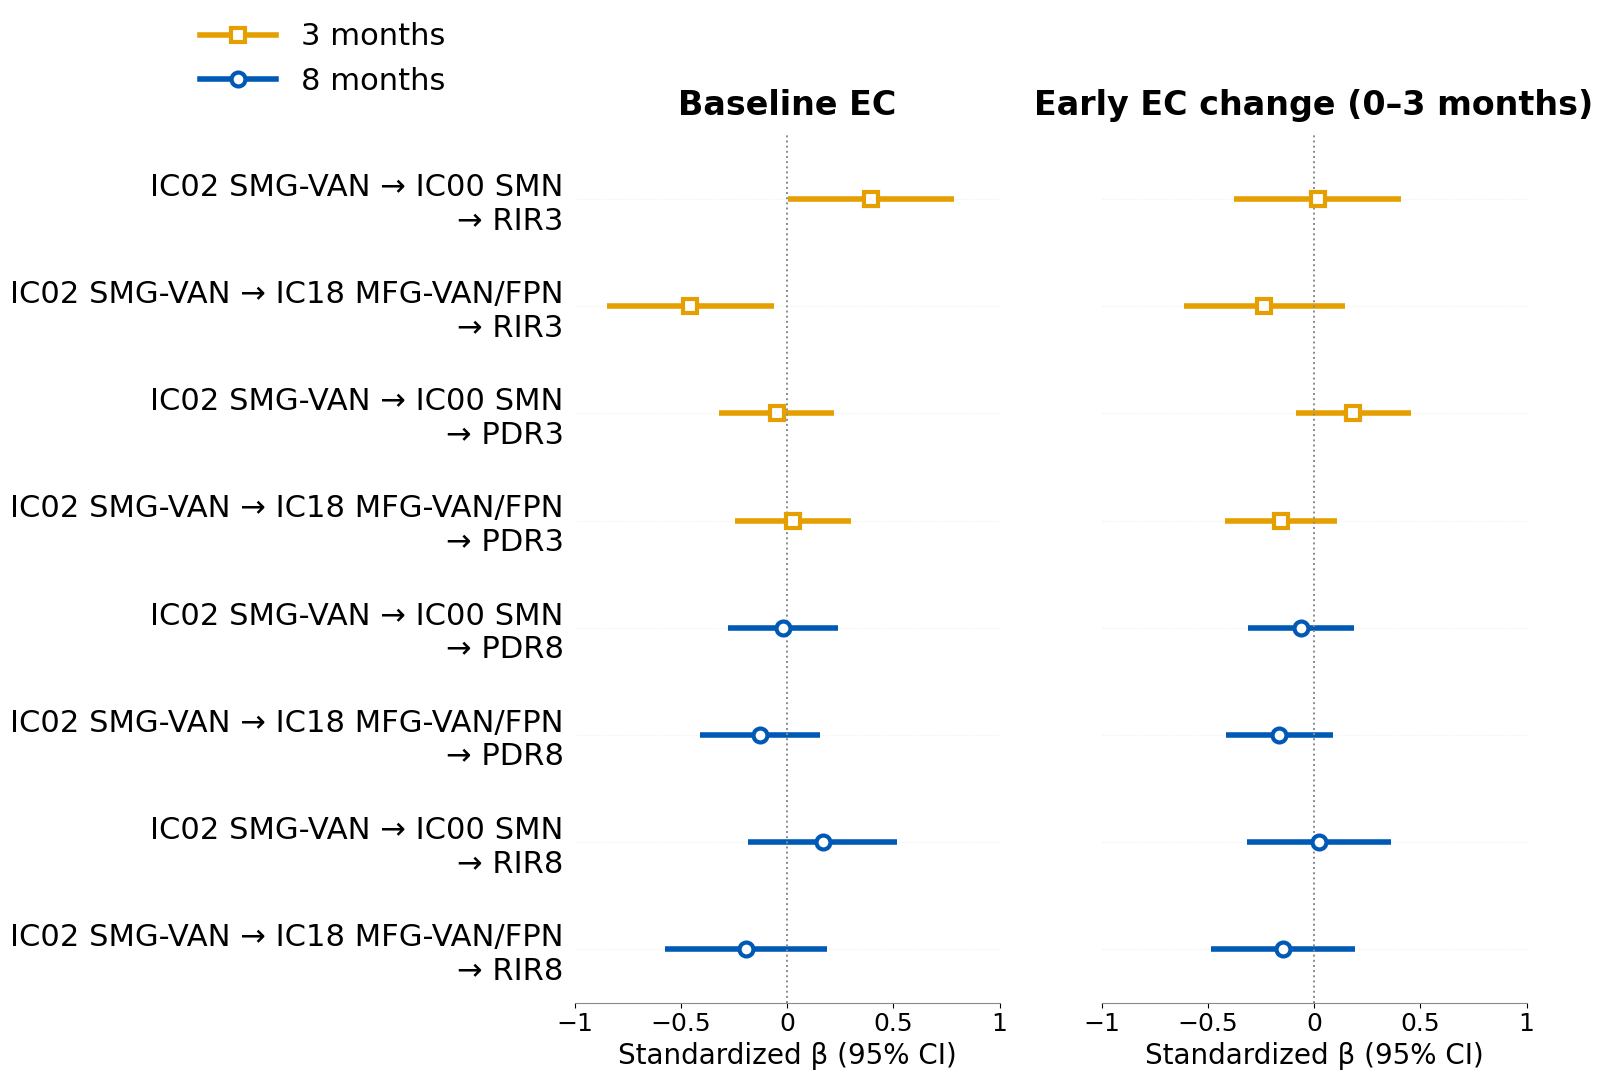

In [13]:
# Figure 5b: full-model neural-clinical estimates.
# Aim: show all 16 associations; method: existing standardized coefficients and native
# Wald intervals; output: one two-panel figure, independent of the omission blocks.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, FuncFormatter

# Figure settings. These can be changed without changing the fitted models.
fig5b_save_figs = 1
fig5b_size = (14, 14)
fig5b_xlim = (-1, 1)  # Set the same tuple here and in Figure 6 for manually fixed limits.
fig5b_font = 18
fig5b_linewidth = 4
fig5b_markersize = 10

fig5b_colors = {3: '#E69F00', 8: '#005AB5'}
fig5b_model = '3_Two_early_changes'
fig5b_outcomes = ['RBANS_inc_rate_3', 'PANSS_dec_rate_3',
                  'PANSS_dec_rate_8', 'RBANS_inc_rate_8']
fig5b_short = dict(zip(fig5b_outcomes, ['RIR3', 'PDR3', 'PDR8', 'RIR8']))
fig5b_edges = [
    ('SalVentA_to_SMN', 'IC02 SMG-VAN → IC00 SMN'),
    ('SalVentA_to_SalVentB', 'IC02 SMG-VAN → IC18 MFG-VAN/FPN'),
]
fig5b_families = [('Baseline EC', 'EC0_'), ('Early EC change (0–3 months)', 'D3_')]

fig5b_native = sem_paths.loc[
    sem_paths.Model.eq(fig5b_model) & sem_paths.op.eq('~')].copy()
fig5b_native = fig5b_native.set_index(['lval', 'rval'])
fig5b_keys = [(outcome, prefix + edge)
             for _, prefix in fig5b_families
             for outcome in fig5b_outcomes for edge, _ in fig5b_edges]
fig5b_all = fig5b_native.loc[fig5b_keys]
fig5b_bounds = np.r_[fig5b_all.SEM_CI95_low_Beta_plugin,
                     fig5b_all.SEM_CI95_high_Beta_plugin, fig5b_all.Beta, 0.0]
fig5b_low, fig5b_high = float(fig5b_bounds.min()), float(fig5b_bounds.max())
fig5b_padding = max((fig5b_high - fig5b_low) * 0.07, 0.03)
if fig5b_xlim is None:
    fig5b_ticks = MaxNLocator(nbins=6).tick_values(
        fig5b_low - fig5b_padding, fig5b_high + fig5b_padding)
    fig5b_xlim = (float(fig5b_ticks[0]), float(fig5b_ticks[-1]))
else:
    fig5b_ticks = np.linspace(fig5b_xlim[0], fig5b_xlim[1], 5)
fig5b_info = fig5b_all.iloc[0]
fig5b_cohort = (f'N = {int(fig5b_info.N)}; control = {int(fig5b_info.Control_N)}, '
                f'meditation = {int(fig5b_info.Meditation_N)}')
fig5b_labels = [name + '\n→ ' + fig5b_short[outcome]
                for outcome in fig5b_outcomes for _, name in fig5b_edges]

fig, axes = plt.subplots(1, 2, figsize=fig5b_size, sharey=True)
fig.subplots_adjust(left=0.30, right=0.98, top=0.78, bottom=0.16, wspace=0.24)
for ax, (title, prefix) in zip(axes, fig5b_families):
    keys = [(outcome, prefix + edge)
            for outcome in fig5b_outcomes for edge, _ in fig5b_edges]
    rows = fig5b_native.loc[keys].reset_index()
    for j, row in enumerate(rows.itertuples(index=False)):
        month = int(row.lval[-1])
        color = fig5b_colors[month]
        marker = 's' if month == 3 else 'o'
        ax.hlines(j, row.SEM_CI95_low_Beta_plugin, row.SEM_CI95_high_Beta_plugin,
                  color=color, linewidth=fig5b_linewidth, zorder=2)
        ax.plot(row.Beta, j, marker=marker, linestyle='none', color=color,
                markersize=fig5b_markersize, markerfacecolor='white',
                markeredgewidth=3, zorder=3)
    ax.set_title(title, fontsize=fig5b_font + 6, fontweight='bold', pad=14)
    ax.set_xlim(fig5b_xlim)
    ax.set_xticks(fig5b_ticks)
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda value, position: f'{value:g}'.replace('-', '−')))
    ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.4)
    ax.set_xlabel('Standardized β (95% CI)', fontsize=fig5b_font + 2)
    ax.tick_params(axis='x', labelsize=fig5b_font)
    ax.tick_params(axis='y', length=0, pad=8)
    ax.grid(axis='y', linestyle=':', alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#858b92')
axes[0].set_yticks(range(len(fig5b_labels)))
axes[0].set_yticklabels(fig5b_labels, fontsize=fig5b_font+4)
axes[0].set_ylim(len(fig5b_labels) - 0.50, -0.60)
axes[1].tick_params(axis='y', labelleft=False)

#fig.suptitle('Neural–clinical associations in the full model', fontsize=18, y=0.99)
#fig.text(0.64, 0.945, fig5b_cohort, ha='center', fontsize=11)
fig.legend(handles=[
    Line2D([], [], color=fig5b_colors[3], marker='s', markerfacecolor='white',
           markeredgewidth=3, linewidth=fig5b_linewidth, markersize=fig5b_markersize, label='3 months'),
    Line2D([], [], color=fig5b_colors[8], marker='o', markerfacecolor='white',
           markeredgewidth=3, linewidth=fig5b_linewidth, markersize=fig5b_markersize, label='8 months'),
], loc='upper center', bbox_to_anchor=(0.12, 0.88), ncol=1,
    frameon=False, fontsize=fig5b_font+4, handlelength=2.5, columnspacing=2)
#fig.text(0.5, 0.055,
#         'Points: full-sample β; lines: pointwise 95% Wald intervals, rescaled with fitted SDs held fixed.\n'
#         'All 16 neural–clinical associations are shown; no selection adjustment.',
#         ha='center', fontsize=10.5, linespacing=1.4)
if fig5b_save_figs:
    fig5b_dir = fig_path / 'neural_clinical'
    fig5b_dir.mkdir(parents=True, exist_ok=True)
    for extension in ['svg', 'pdf']:
        fig.savefig(fig5b_dir / ('Figure5_EC_coefficients_CI.' + extension), bbox_inches='tight')
plt.show()

,Model,Outcome_label,In_sample_R2,Adjusted_R2
0,0_Clinical_original_covariates,PDR3,0.606245,0.564797
1,0_Clinical_original_covariates,RIR3,0.213439,0.130643
2,0_Clinical_original_covariates,PDR8,0.725647,0.679921
3,0_Clinical_original_covariates,RIR8,0.508050,0.426058
4,1_Clinical+FD,PDR3,0.646974,0.588137
5,1_Clinical+FD,RIR3,0.218337,0.088059
6,1_Clinical+FD,PDR8,0.744974,0.675422
7,1_Clinical+FD,RIR8,0.532011,0.404378
8,2_Two_baselines,PDR3,0.672330,0.595231
9,2_Two_baselines,RIR3,0.343323,0.188810


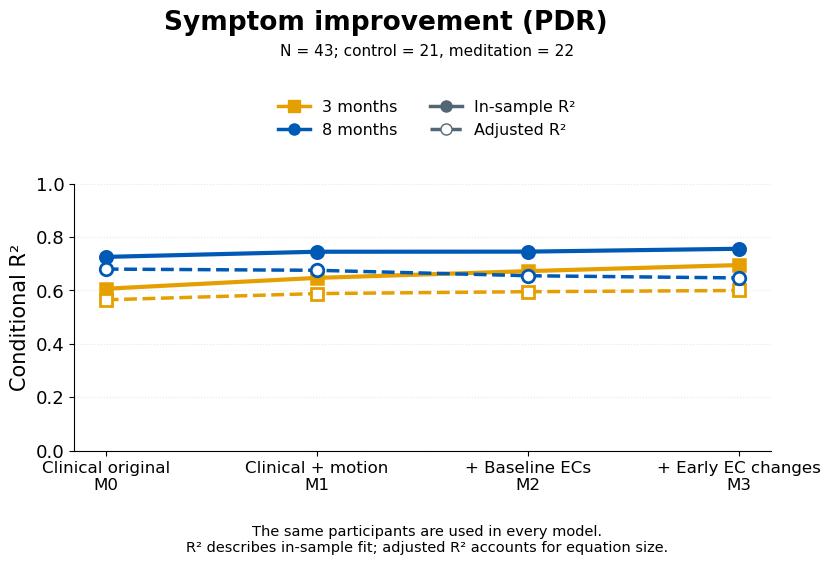

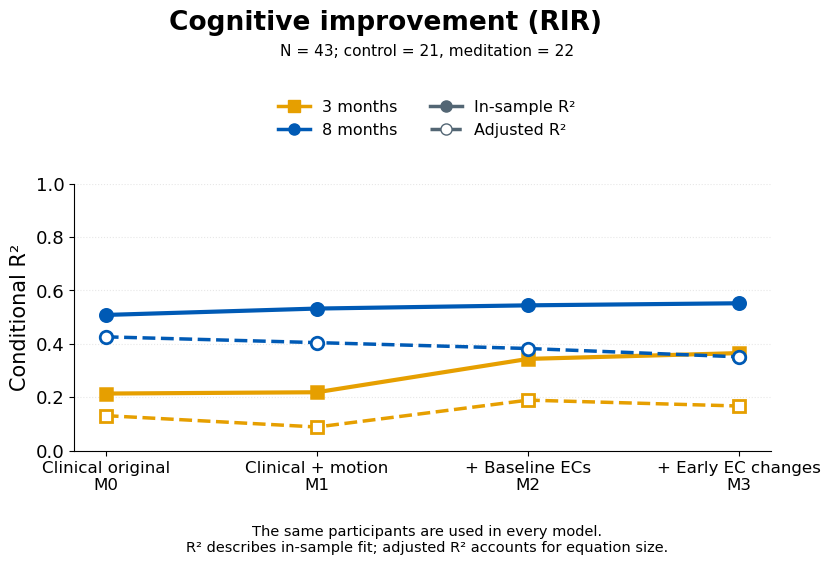

In [14]:
# %% 6. Compare the four models separately for symptoms and cognition.
# Aim: compare months within each clinical domain; method: saved R2 and adjusted R2;
# output: two independent figures, using the same scale and no additional fitting.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

clpm_save_figs = 0

clpm_model_order = list(clpm_model_names)
clpm_tick_names = ['Clinical original\nM0', 'Clinical + motion\nM1', '+ Baseline ECs\nM2', '+ Early EC changes\nM3']
clpm_month_colors = {3: '#E69F00', 8: '#005AB5'}
clpm_n = int(sem_outcomes.N.iloc[0])
clpm_cohort = (f'N = {clpm_n}; control = {int(sem_outcomes.Control_N.iloc[0])}, '
               f'meditation = {int(sem_outcomes.Meditation_N.iloc[0])}')
clpm_ymin = min(0.0, float(sem_outcomes.Adjusted_R2.min()) - 0.04)
clpm_domains = {
    'PDR': ('Symptom improvement (PDR)', [clpm_clinical[0], clpm_clinical[2]]),
    'RIR': ('Cognitive improvement (RIR)', [clpm_clinical[1], clpm_clinical[3]]),
}
display(sem_outcomes[['Model', 'Outcome_label', 'In_sample_R2', 'Adjusted_R2']])

for domain, (title, outcomes) in clpm_domains.items():
    fig, ax = plt.subplots(figsize=(8.2, 5.8))
    fig.subplots_adjust(left=0.12, right=0.97, bottom=0.23, top=0.69)
    for month, outcome, marker in zip([3, 8], outcomes, ['s', 'o']):
        rows = (sem_outcomes.loc[sem_outcomes.Outcome.eq(outcome)]
                .set_index('Model').loc[clpm_model_order])
        color = clpm_month_colors[month]
        ax.plot(range(len(clpm_model_order)), rows.In_sample_R2,
                color=color, marker=marker, linestyle='-', linewidth=3,
                markersize=9, markeredgewidth=1.8)
        ax.plot(range(len(clpm_model_order)), rows.Adjusted_R2,
                color=color, marker=marker, linestyle='--', linewidth=2.5,
                markersize=9, markerfacecolor='white', markeredgewidth=2)
    ax.set_xticks(range(len(clpm_model_order)))
    ax.set_xticklabels(clpm_tick_names, fontsize=12)
    ax.set_ylabel('Conditional R²', fontsize=15)
    ax.set_ylim(clpm_ymin, 1.0)
    ax.tick_params(axis='y', labelsize=13)
    ax.grid(axis='y', linestyle=':', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    handles = [
        Line2D([], [], color=clpm_month_colors[3], marker='s', linewidth=2.5,
               markersize=8, label='3 months'),
        Line2D([], [], color=clpm_month_colors[8], marker='o', linewidth=2.5,
               markersize=8, label='8 months'),
        Line2D([], [], color='#536674', marker='o', linewidth=2.5,
               markersize=8, label='In-sample R²'),
        Line2D([], [], color='#536674', marker='o', linestyle='--', linewidth=2.5,
               markerfacecolor='white', markersize=8, label='Adjusted R²'),
    ]
    fig.suptitle(title, fontsize=19, fontweight='bold', y=0.99)
    fig.text(0.55, 0.91, clpm_cohort, ha='center', fontsize=11)
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.55, 0.86),
               ncol=2, frameon=False, fontsize=11.5)
    fig.text(0.55, 0.055, 'The same participants are used in every model.\n'
             'R² describes in-sample fit; adjusted R² accounts for equation size.',
             ha='center', fontsize=10.5)
    if clpm_save_figs:
        clpm_fig_dir.mkdir(parents=True, exist_ok=True)
        for extension in ['svg', 'pdf']:
            fig.savefig(clpm_fig_dir / ('CLPM_R2_' + domain + '.' + extension),
                        bbox_inches='tight')
    plt.show()

## 7. Separate the baseline and subsequent early-change contributions.

,Baseline ECs,Early EC changes,Total ECs,Adjusted: baseline ECs,Adjusted: early changes,Adjusted: total ECs
Outcome,,,,,,
PANSS_dec_rate_3,0.025356,0.022732,0.048087,0.007095,0.004537,0.011632
PANSS_dec_rate_8,0.000420,0.010709,0.011129,-0.020371,-0.008280,-0.028651
RBANS_inc_rate_3,0.124986,0.021798,0.146784,0.100751,-0.022089,0.078662
RBANS_inc_rate_8,0.012061,0.007801,0.019862,-0.022087,-0.031302,-0.053389


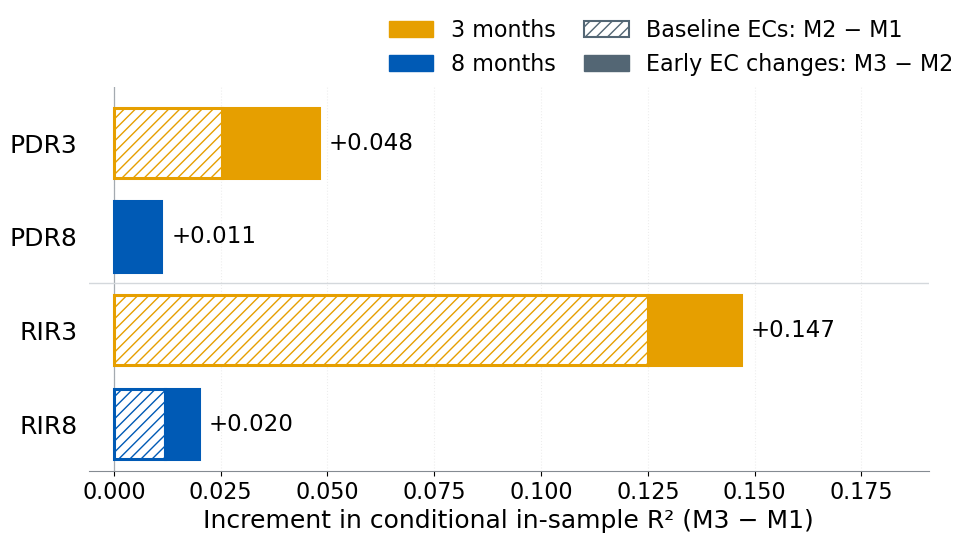

In [15]:
# %% 7. Figure 5c: combined contribution of baseline ECs and early changes.
# Aim: show added in-sample information; method: stack M2-M1 and M3-M2 R2 increments;
# output: one figure labelled with M3-M1 totals and a raw/adjusted-R2 table.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

# Figure settings. Colour identifies month; hatching identifies the added EC block.
fig5c_save_figs = 1
fig5c_size = (10, 8)
fig5c_font = 16
fig5c_barheight = 0.75

fig5c_colors = {3: '#E69F00', 8: '#005AB5'}
fig5c_models = ['1_Clinical+FD', '2_Two_baselines', '3_Two_early_changes']
# Figure 5a numbering: M0 = original clinical reference (not a contrast below).
# M1 = clinical + motion; M2 = M1 + baseline ECs; M3 = M2 + early EC changes.
fig5c_outcomes = ['PANSS_dec_rate_3', 'PANSS_dec_rate_8',
                  'RBANS_inc_rate_3', 'RBANS_inc_rate_8']
fig5c_short = dict(zip(fig5c_outcomes, ['PDR3', 'PDR8', 'RIR3', 'RIR8']))

fig5c_r2 = sem_outcomes.pivot(index='Outcome', columns='Model', values='In_sample_R2')
fig5c_adj = sem_outcomes.pivot(index='Outcome', columns='Model', values='Adjusted_R2')
fig5c_added = pd.DataFrame(index=fig5c_outcomes)
fig5c_added.index.name = 'Outcome'
fig5c_added['Baseline ECs'] = fig5c_r2[fig5c_models[1]] - fig5c_r2[fig5c_models[0]]
fig5c_added['Early EC changes'] = fig5c_r2[fig5c_models[2]] - fig5c_r2[fig5c_models[1]]
fig5c_added['Total ECs'] = fig5c_r2[fig5c_models[2]] - fig5c_r2[fig5c_models[0]]
fig5c_added['Adjusted: baseline ECs'] = fig5c_adj[fig5c_models[1]] - fig5c_adj[fig5c_models[0]]
fig5c_added['Adjusted: early changes'] = fig5c_adj[fig5c_models[2]] - fig5c_adj[fig5c_models[1]]
fig5c_added['Adjusted: total ECs'] = fig5c_adj[fig5c_models[2]] - fig5c_adj[fig5c_models[0]]
display(fig5c_added)
fig5c_info = sem_outcomes.loc[sem_outcomes.Model.eq(fig5c_models[2])].iloc[0]
fig5c_cohort = (f'N = {int(fig5c_info.N)}; control = {int(fig5c_info.Control_N)}, '
                f'meditation = {int(fig5c_info.Meditation_N)}')

def fig5c_number(value):
    if value == 0:
        return '0.000'
    if 0 < value < 0.001:
        return '<0.001'
    if -0.001 < value < 0:
        return '>−0.001'
    return f'{value:+.3f}'

fig, ax = plt.subplots(figsize=fig5c_size)
fig.subplots_adjust(left=0.12, right=0.96, bottom=0.20, top=0.68)
# One bar per outcome: hatched baseline increment, then filled early-change increment.
# Endpoint numbers give the combined EC increment (M3-M1), calculated directly.
for j, outcome in enumerate(fig5c_outcomes):
    color = fig5c_colors[int(outcome[-1])]
    left = 0.0
    for k, label in enumerate(['Baseline ECs', 'Early EC changes']):
        value = float(fig5c_added.loc[outcome, label])
        ax.barh(j, value, left=left, height=fig5c_barheight,
                facecolor='white' if k == 0 else color,
                edgecolor=color, linewidth=2.2, hatch='///' if k == 0 else None, 
                zorder=3)
        left += value
    total = float(fig5c_added.loc[outcome, 'Total ECs'])
    ax.annotate(fig5c_number(total), (total, j),
                xytext=(7 if total >= 0 else -7, 0), textcoords='offset points',
                va='center', ha='left' if total >= 0 else 'right',
                fontsize=fig5c_font + 0.5)
fig5c_values = fig5c_added[['Baseline ECs', 'Total ECs']].to_numpy()
fig5c_extent = max(float(np.abs(fig5c_values).max()), 0.01)
ax.set_xlim(min(0, float(fig5c_values.min())) - 0.04 * fig5c_extent,
            max(0, float(fig5c_values.max())) + 0.30 * fig5c_extent)
ax.set_yticks(range(len(fig5c_outcomes)))
ax.set_yticklabels([fig5c_short[x] for x in fig5c_outcomes], fontsize=fig5c_font + 2)
ax.set_ylim(len(fig5c_outcomes) - 0.5, -0.6)
ax.axhline(1.5, color='#d4d8dc', linewidth=1)
ax.set_xlabel('Increment in conditional in-sample R² (M3 − M1)', fontsize=fig5c_font + 2)
ax.tick_params(axis='x', labelsize=fig5c_font)
ax.tick_params(axis='y', length=0, pad=8)
ax.axvline(0, color='#a4aab0', linewidth=0.9, zorder=1)
ax.grid(axis='x', linestyle=':', alpha=0.22)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#858b92')

#fig.suptitle('Additional in-sample variance explained by ECs', fontsize=18, y=0.99)
#fig.text(0.54, 0.938, fig5c_cohort, ha='center', fontsize=11)
fig.legend(handles=[
    Patch(facecolor=fig5c_colors[3], edgecolor=fig5c_colors[3], label='3 months'),
    Patch(facecolor=fig5c_colors[8], edgecolor=fig5c_colors[8], label='8 months'),
], loc='upper left', bbox_to_anchor=(0.4, 0.79), ncol=1, frameon=False, fontsize=fig5c_font, columnspacing=2)
fig.legend(handles=[
    Patch(facecolor='white', edgecolor='#536674', hatch='///', linewidth=1.5,
          label='Baseline ECs: M2 − M1'),
    Patch(facecolor='#536674', edgecolor='#536674',
          label='Early EC changes: M3 − M2'),
], loc='upper center', bbox_to_anchor=(0.8, 0.79), ncol=1,
    frameon=False, fontsize=fig5c_font)
#fig.text(0.5, 0.055,
#         'M1: clinical + motion; M2: M1 + baseline ECs; M3: M2 + early EC changes.\n'
#         'Endpoint numbers: total M3 − M1. Segments depend on entry order.\n'
#         'No ΔR² uncertainty intervals were estimated.\n'
#         'These describe in-sample fit, not proportions of treatment benefit explained.',
#         ha='center', fontsize=10.5, linespacing=1.4)
if fig5c_save_figs:
    fig5c_dir = fig_path / 'neural_clinical'
    fig5c_dir.mkdir(parents=True, exist_ok=True)
    for extension in ['svg', 'pdf']:
        fig.savefig(fig5c_dir / ('CLPM_EC_R2_contributions.' + extension), bbox_inches='tight')
plt.show()

##  8. Inner stability: Omitting participants

In [16]:
# %% 14. Refit the same semopy models after omitting each participant.
# Aim: assess individual influence; method: unchanged specifications and native fitting,
# with the full-sample input scaling and beta scale held fixed; output: LOO estimates in memory.
# Run the sample preparation and primary semopy blocks first. This block performs new fits.
# It does not reuse the previous OLS omissions or their success counts.
sem_loo_complete = False
sem_loo_paths = None
sem_loo_summary = None
sem_loo_rows = []
for model_name, full_model in sem_models.items():
    loo_full_data = sem_inputs[model_name]
    loo_n = len(loo_full_data)
    loo_reference = sem_paths.loc[
        sem_paths.Model.eq(model_name) & sem_paths.op.eq('~')].copy()
    loo_reference = loo_reference.set_index(['lval', 'rval'])
    loo_order = loo_reference.index
    loo_full_sigma = full_model.calc_sigma()[0]
    loo_full_sd = pd.Series(np.sqrt(np.diag(loo_full_sigma)),
                            index=full_model.vars['observed'])
    loo_beta_scale = np.asarray([
        loo_full_sd[x] / loo_full_sd[y] for y, x in loo_order])
    loo_full_beta = loo_reference['Beta'].to_numpy(dtype=float)

    for omitted_position, participant_id in enumerate(loo_full_data.index):
        loo_input = loo_full_data.iloc[np.arange(loo_n) != omitted_position].copy()
        try:
            loo_model = semopy.Model(sem_specifications[model_name])
            loo_fit = loo_model.fit(loo_input)
            if not loo_fit.success or not np.isfinite(loo_fit.fun):
                raise RuntimeError(str(loo_fit))
            # No uncertainty calculation is needed for the omission point estimates.
            loo_table = loo_model.inspect(information=None, std_est=False)
            loo_estimates = (loo_table.loc[loo_table.op.eq('~')]
                             .set_index(['lval', 'rval'])['Estimate']
                             .reindex(loo_order).to_numpy(dtype=float))
            loo_betas = loo_estimates * loo_beta_scale
            if not np.isfinite(loo_betas).all():
                raise RuntimeError('One or more fitted regression coefficients are unavailable or nonfinite.')
        except Exception as error:
            raise RuntimeError(
                f'{model_name}: omission of {participant_id} did not provide a usable native fit. '
                'Stop here and return this message; do not summarize partial omissions.\n'
                f'{error}') from error

        for j, (outcome, predictor) in enumerate(loo_order):
            sem_loo_rows.append({
                'Model': model_name, 'lval': outcome, 'rval': predictor,
                'Auxiliary': outcome == 'FD8',
                'Full_N': loo_n, 'LOO_N': len(loo_input),
                'Omitted_participant_id': str(participant_id),
                'Full_Beta': loo_full_beta[j],
                'LOO_Estimate': loo_estimates[j], 'LOO_Beta': loo_betas[j],
                'Delta_Beta': loo_betas[j] - loo_full_beta[j],
                'Opposite_sign': bool(loo_betas[j] * loo_full_beta[j] < 0),
                'Fit_success': True,
            })
    print(f'{model_name}: {loo_n}/{loo_n} native semopy omissions completed; '
          f'{loo_n - 1} participants per fit.')

sem_loo_paths = pd.DataFrame(sem_loo_rows)
sem_loo_complete = True
print('Every omission uses the original standardized inputs and the full-model SD conversion to beta.')
# These are refit influence estimates, not held-out predictions, confidence intervals,
# or tests of significance. All selected ECs and covariates remain in every refit.

0_Clinical_original_covariates: 43/43 native semopy omissions completed; 42 participants per fit.
1_Clinical+FD: 43/43 native semopy omissions completed; 42 participants per fit.
2_Two_baselines: 43/43 native semopy omissions completed; 42 participants per fit.
3_Two_early_changes: 43/43 native semopy omissions completed; 42 participants per fit.
Every omission uses the original standardized inputs and the full-model SD conversion to beta.


### 9. Summarize the native-semopy omissions and save two result tables.


In [17]:
# %% 15. Summarize the native-semopy omissions and save two result tables.
# Aim: report every omission transparently; method: coefficient ranges and sign changes;
# output: one participant-level CSV and one summary CSV, retaining all fitted regressions.
if not sem_loo_complete:
    raise RuntimeError('Complete block 14 successfully before exporting or interpreting native-semopy omissions.')
sem_loo_summary_rows = []
for (model_name, outcome, predictor), rows in sem_loo_paths.groupby(
        ['Model', 'lval', 'rval'], sort=False):
    full_beta = float(rows['Full_Beta'].iloc[0])
    sem_loo_summary_rows.append({
        'Model': model_name, 'lval': outcome, 'rval': predictor,
        'Auxiliary': bool(rows['Auxiliary'].iloc[0]),
        'N': int(rows['Full_N'].iloc[0]), 'Full_Beta': full_beta,
        'LOO_requested': int(rows['Full_N'].iloc[0]),
        'LOO_usable': len(rows),
        'LOO_min_Beta': rows['LOO_Beta'].min(),
        'LOO_max_Beta': rows['LOO_Beta'].max(),
        'LOO_opposite_sign_count': int(rows['Opposite_sign'].sum()),
        'LOO_max_abs_difference_Beta': rows['Delta_Beta'].abs().max(),
    })
sem_loo_summary = pd.DataFrame(sem_loo_summary_rows)
sem_loo_paths.to_csv(nc_path / 'Focused_CLPM_semopy_LOO_paths.csv', index=False)
sem_loo_summary.to_csv(nc_path / 'Focused_CLPM_semopy_LOO_summary.csv', index=False)

# Show the same 30 substantive paths as the full neural graph; nuisance paths remain in both files.
sem_loo_display_nodes = set(['treatment'] + fc_outcomes + fc_base + fc_delta)
sem_loo_display = sem_loo_summary.loc[
    sem_loo_summary.Model.eq(fc_names[2]) &
    sem_loo_summary.lval.isin(sem_loo_display_nodes) &
    sem_loo_summary.rval.isin(sem_loo_display_nodes)]
with pd.option_context('display.max_rows', None):
    display(sem_loo_display[['lval', 'rval', 'Full_Beta', 'LOO_min_Beta',
                            'LOO_max_Beta', 'LOO_opposite_sign_count',
                            'LOO_max_abs_difference_Beta', 'LOO_usable', 'LOO_requested']])
print('Saved the two native-semopy LOO tables to:', nc_path)
print('Ranges describe participant influence, not confidence intervals or prediction validation.')
# A sign reversal is defined relative to the full-sample coefficient. A coefficient exactly
# zero has no reference direction; zero sign reversals alone therefore do not establish stability.

,lval,rval,Full_Beta,LOO_min_Beta,LOO_max_Beta,LOO_opposite_sign_count,LOO_max_abs_difference_Beta,LOO_usable,LOO_requested
106,PANSS_dec_rate_3,treatment,0.733212,0.660045,0.839520,0,0.106308,43,43
110,PANSS_dec_rate_3,EC0_SalVentA_to_SMN,-0.049347,-0.095456,0.009805,1,0.059152,43,43
111,PANSS_dec_rate_3,EC0_SalVentA_to_SalVentB,0.027290,-0.142431,0.097679,4,0.169721,43,43
112,PANSS_dec_rate_3,D3_SalVentA_to_SMN,0.184827,0.116841,0.238957,0,0.067986,43,43
113,PANSS_dec_rate_3,D3_SalVentA_to_SalVentB,-0.154103,-0.267012,-0.081439,0,0.112909,43,43
116,RBANS_inc_rate_3,treatment,0.420652,0.333978,0.524303,0,0.103651,43,43
120,RBANS_inc_rate_3,EC0_SalVentA_to_SMN,0.392733,0.185513,0.587566,0,0.207220,43,43
121,RBANS_inc_rate_3,EC0_SalVentA_to_SalVentB,-0.455758,-0.540849,-0.383325,0,0.085090,43,43
122,RBANS_inc_rate_3,D3_SalVentA_to_SMN,0.016963,-0.085049,0.152262,8,0.135299,43,43
123,RBANS_inc_rate_3,D3_SalVentA_to_SalVentB,-0.234046,-0.364681,-0.132337,0,0.130636,43,43


Saved the two native-semopy LOO tables to: /scratch/repo_sz_meditation/data/neural_clinical
Ranges describe participant influence, not confidence intervals or prediction validation.


## 10. Compare native uncertainty and participant-omission sensitivity.

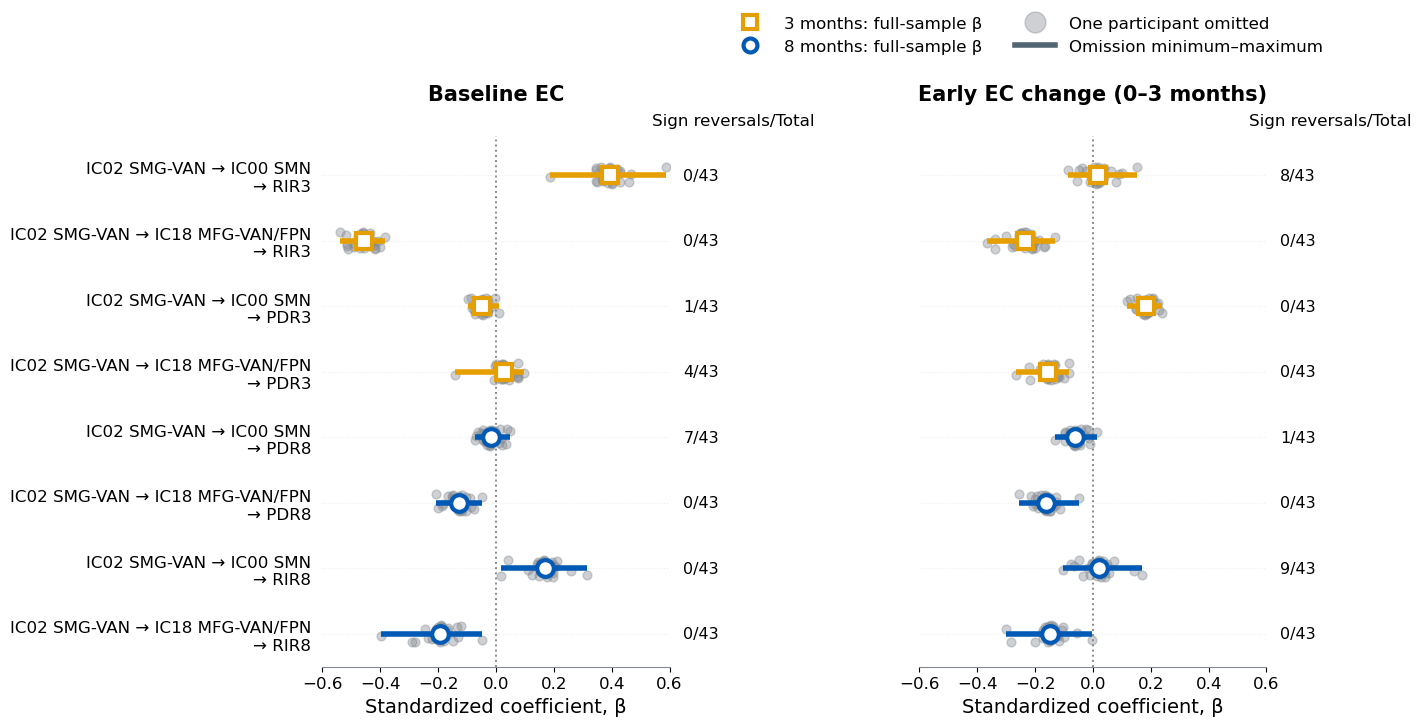

In [18]:
# %% 10.2. Figure 6: leave-one-participant-out influence.
# Aim: show individual influence on all 16 associations; method: existing semopy
# omission estimates on the full-model scale; output: one two-panel figure, no refitting.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# Figure settings. Row order and month colours match Figure 5b.
fig6_save_figs = 1
fig6_size = (16, 9)
fig6_xlim = (-0.6, 0.6)  # Set the same tuple here and in Figure 5b for manually fixed limits.
fig6_font = 12
fig6_linewidth = 4
fig6_markersize = 12

fig6_colors = {3: '#E69F00', 8: '#005AB5'}
fig6_model = '3_Two_early_changes'
fig6_outcomes = ['RBANS_inc_rate_3', 'PANSS_dec_rate_3',
                 'PANSS_dec_rate_8', 'RBANS_inc_rate_8']
fig6_short = dict(zip(fig6_outcomes, ['RIR3', 'PDR3', 'PDR8', 'RIR8']))
fig6_edges = [
    ('SalVentA_to_SMN', 'IC02 SMG-VAN → IC00 SMN'),
    ('SalVentA_to_SalVentB', 'IC02 SMG-VAN → IC18 MFG-VAN/FPN'),
]
fig6_families = [('Baseline EC', 'EC0_'), ('Early EC change (0–3 months)', 'D3_')]

# Sections 8 and 9 must already have produced the omission tables.
fig6_native = sem_paths.loc[
    sem_paths.Model.eq(fig6_model) & sem_paths.op.eq('~')].copy()
fig6_native = fig6_native.merge(
    sem_loo_summary.loc[sem_loo_summary.Model.eq(fig6_model)],
    on=['Model', 'lval', 'rval'], suffixes=('', '_LOO'), validate='one_to_one')
fig6_native = fig6_native.set_index(['lval', 'rval'])
fig6_omissions = sem_loo_paths.loc[sem_loo_paths.Model.eq(fig6_model)]
fig6_keys = [(outcome, prefix + edge)
            for _, prefix in fig6_families
            for outcome in fig6_outcomes for edge, _ in fig6_edges]
fig6_all = fig6_native.loc[fig6_keys]
# Include the Figure 5b interval envelope so current figures retain matching axes.
fig6_bounds = np.r_[fig6_all.SEM_CI95_low_Beta_plugin,
                    fig6_all.SEM_CI95_high_Beta_plugin, fig6_all.Beta,
                    fig6_all.LOO_min_Beta, fig6_all.LOO_max_Beta, 0.0]
fig6_low, fig6_high = float(fig6_bounds.min()), float(fig6_bounds.max())
fig6_padding = max((fig6_high - fig6_low) * 0.07, 0.03)
if fig6_xlim is None:
    fig6_ticks = MaxNLocator(nbins=6).tick_values(
        fig6_low - fig6_padding, fig6_high + fig6_padding)
    fig6_xlim = (float(fig6_ticks[0]), float(fig6_ticks[-1]))
else:
    fig6_ticks = np.linspace(fig6_xlim[0], fig6_xlim[1], 7)
fig6_info = fig6_all.iloc[0]
fig6_n = int(fig6_info.N)
fig6_cohort = (f'N = {fig6_n}; control = {int(fig6_info.Control_N)}, '
               f'meditation = {int(fig6_info.Meditation_N)}')
fig6_labels = [name + '\n→ ' + fig6_short[outcome]
               for outcome in fig6_outcomes for _, name in fig6_edges]

fig, axes = plt.subplots(1, 2, figsize=fig6_size, sharey=True)
fig.subplots_adjust(left=0.29, right=0.88, top=0.75, bottom=0.16, wspace=0.72)
for ax, (title, prefix) in zip(axes, fig6_families):
    keys = [(outcome, prefix + edge)
            for outcome in fig6_outcomes for edge, _ in fig6_edges]
    rows = fig6_native.loc[keys].reset_index()
    for j, row in enumerate(rows.itertuples(index=False)):
        month = int(row.lval[-1])
        color = fig6_colors[month]
        marker = 's' if month == 3 else 'o'
        values = fig6_omissions.loc[
            fig6_omissions.lval.eq(row.lval) & fig6_omissions.rval.eq(row.rval),
            'LOO_Beta'].to_numpy()
        offsets = np.linspace(-0.13, 0.13, len(values))
        ax.scatter(values, j + offsets, s=40, color='#858b92', alpha=0.4, zorder=2)
        ax.hlines(j, row.LOO_min_Beta, row.LOO_max_Beta,
                  color=color, linewidth=fig6_linewidth, zorder=3)
        ax.plot(row.Beta, j, marker=marker, linestyle='none', color=color,
                markersize=fig6_markersize, markerfacecolor='white',
                markeredgewidth=3, zorder=4)
        ax.text(1.04, j, f'{int(row.LOO_opposite_sign_count)}/{int(row.LOO_usable)}',
                 transform=ax.get_yaxis_transform(), va='center', fontsize=fig6_font - 0.5)
    ax.set_title(title, fontsize=fig6_font + 3, fontweight='bold', pad=26)
    ax.set_xlim(fig6_xlim)
    ax.set_xticks(fig6_ticks)
    ax.axvline(0, color='#858b92', linestyle=':', linewidth=1.4)
    ax.set_xlabel('Standardized coefficient, β', fontsize=fig6_font + 2)
    ax.tick_params(axis='x', labelsize=fig6_font)
    ax.tick_params(axis='y', length=0, pad=8)
    ax.grid(axis='y', linestyle=':', alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#858b92')
    ax.text(0.95, 1.015, 'Sign reversals/Total', transform=ax.transAxes,
             fontsize=12, va='bottom')
axes[0].set_yticks(range(len(fig6_labels)))
axes[0].set_yticklabels(fig6_labels, fontsize=fig6_font)
axes[0].set_ylim(len(fig6_labels) - 0.50, -0.60)
axes[1].tick_params(axis='y', labelleft=False)

#fig.suptitle('Leave-one-participant-out influence', fontsize=18, y=0.99)
#fig.text(0.61, 0.946, fig6_cohort, ha='center', fontsize=11)
fig.legend(handles=[
    Line2D([], [], color=fig6_colors[3], marker='s', linestyle='none',
           markerfacecolor='white', markeredgewidth=3, markersize=10,
           label='3 months: full-sample β'),
    Line2D([], [], color=fig6_colors[8], marker='o', linestyle='none',
           markerfacecolor='white', markeredgewidth=3, markersize=10,
           label='8 months: full-sample β'),
    Line2D([], [], color='#858b92', marker='o', linestyle='none', markersize=15, alpha=0.4,
           label='One participant omitted'),
    Line2D([], [], color='#536674', linewidth=4, label='Omission minimum–maximum'),
], loc='upper center', bbox_to_anchor=(0.73, 0.9), ncol=2,
    frameon=False, fontsize=fig6_font, handlelength=2.4, columnspacing=2)
#fig.text(0.5, 0.055,
#         f'{fig6_n} omissions; N = {fig6_n - 1} per refit; full-model coefficient scales held fixed.\n'
#         'Ranges describe individual influence, not confidence intervals or prediction validation.',
#         ha='center', fontsize=10.5, linespacing=1.4)
if fig6_save_figs:
    fig6_dir = fig_path / 'neural_clinical'
    fig6_dir.mkdir(parents=True, exist_ok=True)
    for extension in ['svg', 'pdf']:
        fig.savefig(fig6_dir / ('Figure6_EC_participant_omissions.' + extension), bbox_inches='tight')
plt.show()